In [ ]:
!pip -q install numpy pandas plotly ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 26.7 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

from IPython.display import display
import ipywidgets as widgets

In [ ]:
def folded_zero(N):
    """
    Finite QTET folded-zero construction:

        0_N = 0 + Σ[n + (-n)], n = 1...N

    Every lawful inverse pair closes to zero.
    """

    if N < 1:
        raise ValueError("N must be >= 1")

    positive = np.arange(1, N + 1)
    negative = -positive

    pair_sum = positive + negative

    total = pair_sum.sum()

    return {
        "N": N,
        "positive": positive,
        "negative": negative,
        "pair_sum": pair_sum,
        "total": total
    }

In [ ]:
for N in [1, 10, 100, 1_000, 100_000]:
    result = folded_zero(N)

    print(
        f"N = {N:>7,}   "
        f"pairs = {len(result['pair_sum']):>7,}   "
        f"result = {result['total']}"
    )

N =       1   pairs =       1   result = 0
N =      10   pairs =      10   result = 0
N =     100   pairs =     100   result = 0
N =   1,000   pairs =   1,000   result = 0
N = 100,000   pairs = 100,000   result = 0


In [ ]:
def plot_number_line(N=10):

    states = np.arange(-N, N + 1)

    fig = go.Figure()

    fig.add_trace(
        go.Scatter(
            x=states,
            y=np.zeros_like(states),
            mode="markers+text",
            text=states,
            textposition="top center",
            marker=dict(size=10),
            name="Lawful numerical states"
        )
    )

    fig.add_trace(
        go.Scatter(
            x=[0],
            y=[0],
            mode="markers",
            marker=dict(size=20, symbol="diamond"),
            name="0 reference"
        )
    )

    fig.update_layout(
        title=f"Sequential Number-Line Representation | N = {N}",
        xaxis_title="Numerical state",
        yaxis_visible=False,
        height=350
    )

    fig.show()

In [ ]:
plot_number_line(10)

In [ ]:
def folded_coordinates(N):

    n = np.arange(1, N + 1)

    # Angular locations distributed around a circle
    theta = 2 * np.pi * (n - 1) / N

    # Positive branch

In [ ]:
def folded_coordinates(N):
    """
    Visualization coordinates only.

    +n and -n remain distinct lawful numerical states,
    while their inverse-pair relationship is made geometrically visible.
    """

    n = np.arange(1, N + 1)

    # Spread pairs around a circle
    theta = 2 * np.pi * (n - 1) / N

    # Radius grows with |n|
    radius = n / N

    # +n branch
    x_pos = radius * np.cos(theta)
    y_pos = radius * np.sin(theta)

    # -n branch mirrored through the origin
    x_neg = -x_pos
    y_neg = -y_pos

    return {
        "n": n,
        "theta": theta,
        "radius": radius,
        "x_pos": x_pos,
        "y_pos": y_pos,
        "x_neg": x_neg,
        "y_neg": y_neg
    }

In [ ]:
def plot_folded_zero(N=12):

    coords = folded_coordinates(N)

    fig = go.Figure()

    # Draw inverse-pair relationships
    for i, n in enumerate(coords["n"]):

        fig.add_trace(
            go.Scatter(
                x=[
                    coords["x_pos"][i],
                    0,
                    coords["x_neg"][i]
                ],
                y=[
                    coords["y_pos"][i],
                    0,
                    coords["y_neg"][i]
                ],
                mode="lines",
                line=dict(width=1),
                showlegend=False,
                hoverinfo="skip"
            )
        )

    # Positive states
    fig.add_trace(
        go.Scatter(
            x=coords["x_pos"],
            y=coords["y_pos"],
            mode="markers+text",
            text=[f"+{n}" for n in coords["n"]],
            textposition="top center",
            marker=dict(size=10),
            name="+n"
        )
    )

    # Negative states
    fig.add_trace(
        go.Scatter(
            x=coords["x_neg"],
            y=coords["y_neg"],
            mode="markers+text",
            text=[f"-{n}" for n in coords["n"]],
            textposition="bottom center",
            marker=dict(size=10),
            name="-n"
        )
    )

    # Folded total-state reference
    fig.add_trace(
        go.Scatter(
            x=[0],
            y=[0],
            mode="markers+text",
            text=["0"],
            textposition="middle center",
            marker=dict(
                size=28,
                symbol="circle"
            ),
            name="0 — folded total-state reference"
        )
    )

    fig.update_layout(
        title=f"Folded Inverse-Pair Representation | N = {N}",
        xaxis=dict(
            visible=False,
            scaleanchor="y",
            scaleratio=1
        ),
        yaxis=dict(
            visible=False
        ),
        height=650,
        showlegend=True
    )

    fig.show()

In [ ]:
plot_folded_zero(12)

In [ ]:
def simultaneous_state_string(N=5):

    negative = list(range(-N, 0))
    positive = list(range(1, N + 1))

    states = negative + [0] + positive

    state_text = ", ".join(str(x) for x in states)

    return "{ " + state_text + " }^||"

In [ ]:
print(simultaneous_state_string(5))

{ -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5 }^||


In [ ]:
def pair_closure_table(N=10):

    n = np.arange(1, N + 1)

    df = pd.DataFrame({
        "n": n,
        "+n": n,
        "-n": -n,
        "pair closure": n + (-n)
    })

    return df

In [ ]:
display(pair_closure_table(10))

,n,+n,-n,pair closure
0,1,1,-1,0
1,2,2,-2,0
2,3,3,-3,0
3,4,4,-4,0
4,5,5,-5,0
5,6,6,-6,0
6,7,7,-7,0
7,8,8,-8,0
8,9,9,-9,0
9,10,10,-10,0


In [ ]:
def boundary_growth(max_power=6):

    N_values = np.array([
        10**p for p in range(max_power + 1)
    ])

    state_counts = 2 * N_values + 1

    closure_values = []

    for N in N_values:

        n = np.arange(1, N + 1, dtype=np.int64)

        closure = np.sum(n + (-n))

        closure_values.append(closure)

    return pd.DataFrame({
        "N": N_values,
        "represented_states": state_counts,
        "closure": closure_values
    })

In [ ]:
growth = boundary_growth(6)

display(growth)

,N,represented_states,closure
0,1,3,0
1,10,21,0
2,100,201,0
3,1000,2001,0
4,10000,20001,0
5,100000,200001,0
6,1000000,2000001,0


In [ ]:
def plot_boundary_growth(df):

    fig = go.Figure()

    fig.add_trace(
        go.Scatter(
            x=df["N"],
            y=df["represented_states"],
            mode="lines+markers",
            name="Represented lawful states"
        )
    )

    fig.add_trace(
        go.Scatter(
            x=df["N"],
            y=df["closure"],
            mode="lines+markers",
            name="Pair closure"
        )
    )

    fig.update_layout(
        title="Increasing Boundary vs. Finite Closure",
        xaxis=dict(
            title="Boundary N",
            type="log"
        ),
        yaxis_title="Value",
        height=500
    )

    fig.show()

In [ ]:
plot_boundary_growth(growth)

In [ ]:
N_slider = widgets.IntSlider(
    value=8,
    min=1,
    max=40,
    step=1,
    description="Boundary N:",
    continuous_update=False
)

display(
    widgets.interactive(
        plot_folded_zero,
        N=N_slider
    )
)

interactive(children=(IntSlider(value=8, continuous_update=False, description='Boundary N:', max=40, min=1), O…

In [ ]:
def project_state(n, N):

    if abs(n) > N:
        raise ValueError(
            f"State {n} lies outside the selected finite boundary ±{N}."
        )

    return n

In [ ]:
N = 20

for target in [-12, -3, 0, 7, 18]:
    print(
        f"π_{target}(0_Q) →",
        project_state(target, N)
    )

π_-12(0_Q) → -12
π_-3(0_Q) → -3
π_0(0_Q) → 0
π_7(0_Q) → 7
π_18(0_Q) → 18


In [ ]:
class FoldedTotalState:
    def __repr__(self):
        return "0_Q"


ZERO_Q = FoldedTotalState()


def rho(n):
    return ZERO_Q

In [ ]:
for n in [-100, -2, 0, 4, 91]:

    projected = n
    returned = rho(projected)

    print(
        f"π_{n}(0_Q) = {projected:>4}   "
        f"ρ({projected}) = {returned}"
    )

π_-100(0_Q) = -100   ρ(-100) = 0_Q
π_-2(0_Q) =   -2   ρ(-2) = 0_Q
π_0(0_Q) =    0   ρ(0) = 0_Q
π_4(0_Q) =    4   ρ(4) = 0_Q
π_91(0_Q) =   91   ρ(91) = 0_Q


In [ ]:
0

0

In [ ]:
def animate_projection_return(n=7, frames=50):

    magnitude = abs(n)

    if magnitude == 0:
        magnitude = 1

    # Outward projection
    outward = np.linspace(0, magnitude, frames)

    # Return
    inward = np.linspace(magnitude, 0, frames)

    path = np.concatenate([outward, inward])

    direction = 1 if n >= 0 else -1

    x_path = direction * path

    fig = go.Figure(
        data=[
            go.Scatter(
                x=[x_path[0]],
                y=[0],
                mode="markers",
                marker=dict(size=22)
            )
        ],
        layout=go.Layout(
            title=f"π_{n}(0_Q) → n → ρ(n) → 0_Q",
            xaxis=dict(
                range=[-magnitude - 1, magnitude + 1],
                title="Differentiated state"
            ),
            yaxis=dict(
                range=[-1, 1],
                visible=False
            ),
            height=350,
            updatemenus=[
                dict(
                    type="buttons",
                    buttons=[
                        dict(
                            label="Play",
                            method="animate",
                            args=[
                                None,
                                {
                                    "frame": {
                                        "duration": 35,
                                        "redraw": True
                                    },
                                    "fromcurrent": True
                                }
                            ]
                        )
                    ]
                )
            ]
        ),
        frames=[
            go.Frame(
                data=[
                    go.Scatter(
                        x=[x],
                        y=[0],
                        mode="markers",
                        marker=dict(size=22)
                    )
                ]
            )
            for x in x_path
        ]
    )

    fig.show()

In [ ]:
animate_projection_return(-8)

In [ ]:
def zero_scaling_experiment(
    boundaries=(10, 100, 1_000, 10_000, 100_000, 1_000_000)
):

    records = []

    for N in boundaries:

        n = np.arange(
            1,
            N + 1,
            dtype=np.int64
        )

        closure = np.sum(n + (-n))

        records.append({
            "boundary_N": N,
            "positive_states": N,
            "negative_states": N,
            "total_represented_states": 2 * N + 1,
            "pair_closure": closure,
            "closure_preserved": closure == 0
        })

    return pd.DataFrame(records)

In [ ]:
zero_results = zero_scaling_experiment()

display(zero_results)

,boundary_N,positive_states,negative_states,total_represented_states,pair_closure,closure_preserved
0,10,10,10,21,0,True
1,100,100,100,201,0,True
2,1000,1000,1000,2001,0,True
3,10000,10000,10000,20001,0,True
4,100000,100000,100000,200001,0,True
5,1000000,1000000,1000000,2000001,0,True


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=zero_results)

In [ ]:
zero_results.to_csv(
    "QTET_inside_zero_scaling_results.csv",
    index=False
)

print("Saved: QTET_inside_zero_scaling_results.csv")

In [ ]:
P2_KERNEL = (
    (3, 3),
    (0, 0),
    (0, 1),
    (1, 2),
    (2, 1),
    (1, 0),
    (0, 0),
)

DELAY = 200

P2_STAGE_NAMES = (
    "Bounded triadic entry",
    "Folded total-state reference after entry",
    "Differentiated traversal state",
    "Relational transition",
    "Inversion-paired transition",
    "Return-directed traversal",
    "Return to folded total-state reference",
)

print("Tensor P2:")
print(" → ".join(f"{x},{y}" for x, y in P2_KERNEL))
print(f" → Delay({DELAY})")

In [ ]:
def p2_table():
    rows = []

    for step, ((x, y), meaning) in enumerate(
        zip(P2_KERNEL, P2_STAGE_NAMES)
    ):
        rows.append({
            "step": step,
            "x": x,
            "y": y,
            "state": f"{x},{y}",
            "role": meaning
        })

    rows.append({
        "step": len(P2_KERNEL),
        "x": None,
        "y": None,
        "state": f"Delay({DELAY})",
        "role": "Temporal spacing after return"
    })

    return pd.DataFrame(rows)


p2_df = p2_table()
display(p2_df)

In [ ]:
def verify_p2_kernel():

    expected = (
        (3, 3),
        (0, 0),
        (0, 1),
        (1, 2),
        (2, 1),
        (1, 0),
        (0, 0),
    )

    checks = {
        "exact_kernel_match": P2_KERNEL == expected,
        "entry_is_3_3": P2_KERNEL[0] == (3, 3),
        "first_reference_is_0_0": P2_KERNEL[1] == (0, 0),
        "final_return_is_0_0": P2_KERNEL[-1] == (0, 0),
        "delay_is_200": DELAY == 200,
        "kernel_length_is_7": len(P2_KERNEL) == 7,
    }

    return pd.DataFrame(
        checks.items(),
        columns=["check", "passed"]
    )


display(verify_p2_kernel())

In [ ]:
def echolift():
    """
    Forward Tensor P2 traversal.
    """
    return tuple(P2_KERNEL)


def rosenecho():
    """
    Reverse Tensor P2 traversal.
    """
    return tuple(reversed(P2_KERNEL))


print("EchoLift:")
print(" → ".join(f"{x},{y}" for x, y in echolift()))

print()

print("RosenEcho:")
print(" → ".join(f"{x},{y}" for x, y in rosenecho()))

In [ ]:
def traversal_identity_test():

    original = tuple(P2_KERNEL)

    forward = echolift()

    reverse = tuple(reversed(forward))

    recovered = tuple(reversed(reverse))

    return {
        "original": original,
        "forward": forward,
        "reverse": reverse,
        "recovered": recovered,
        "identity_preserved": recovered == original
    }


identity = traversal_identity_test()

print("Identity preserved:",
      identity["identity_preserved"])

In [ ]:
def plot_p2_board():

    x = [state[0] for state in P2_KERNEL]
    y = [state[1] for state in P2_KERNEL]

    fig = go.Figure()

    # Accessible display board
    for xi in range(4):
        for yi in range(4):
            fig.add_trace(
                go.Scatter(
                    x=[xi],
                    y=[yi],
                    mode="markers",
                    marker=dict(
                        size=8,
                        opacity=0.20
                    ),
                    showlegend=False,
                    hoverinfo="skip"
                )
            )

    # Tensor P2 trajectory
    fig.add_trace(
        go.Scatter(
            x=x,
            y=y,
            mode="lines+markers",
            marker=dict(size=18),
            line=dict(width=4),
            name="Tensor P2"
        )
    )

    # Traversal-stage annotations
    for i, ((xi, yi), role) in enumerate(
        zip(P2_KERNEL, P2_STAGE_NAMES)
    ):

        text = f"{i}: {xi},{yi}<br>{role}"

        # Offset repeated zero labels
        if i == 1:
            ax, ay = -100, -70
        elif i == 6:
            ax, ay = 100, 70
        else:
            ax, ay = 40, -45

        fig.add_annotation(
            x=xi,
            y=yi,
            text=text,
            showarrow=True,
            ax=ax,
            ay=ay
        )

    fig.update_layout(
        title="Tensor P2 — Fixed State-Space Traversal",
        xaxis=dict(
            title="First coordinate",
            tickmode="linear",
            dtick=1,
            range=[-0.5, 3.5]
        ),
        yaxis=dict(
            title="Second coordinate",
            tickmode="linear",
            dtick=1,
            range=[-0.5, 3.5],
            scaleanchor="x",
            scaleratio=1
        ),
        width=750,
        height=700
    )

    fig.show()

In [ ]:
plot_p2_board()

In [ ]:
def animate_echolift():

    sequence = list(P2_KERNEL)

    x_path = [s[0] for s in sequence]
    y_path = [s[1] for s in sequence]

    fig = go.Figure()

    # Entire invariant path
    fig.add_trace(
        go.Scatter(
            x=x_path,
            y=y_path,
            mode="lines+markers",
            marker=dict(
                size=9,
                opacity=0.35
            ),
            line=dict(
                width=2
            ),
            name="P2 invariant path"
        )
    )

    # Active traversal state
    fig.add_trace(
        go.Scatter(
            x=[x_path[0]],
            y=[y_path[0]],
            mode="markers+text",
            text=["3,3"],
            textposition="top center",
            marker=dict(size=26),
            name="EchoLift"
        )
    )

    frames = []

    for i, ((x, y), role) in enumerate(
        zip(sequence, P2_STAGE_NAMES)
    ):

        frames.append(
            go.Frame(
                name=str(i),
                data=[
                    go.Scatter(
                        x=[x],
                        y=[y],
                        mode="markers+text",
                        text=[f"{x},{y}"],
                        textposition="top center",
                        marker=dict(size=26)
                    )
                ],
                traces=[1],
                layout=go.Layout(
                    title_text=(
                        f"EchoLift — Step {i}"
                        f"<br><sup>{role}</sup>"
                    )
                )
            )
        )

    fig.frames = frames

    fig.update_layout(
        title=(
            "EchoLift — Tensor P2 Forward Traversal"
            "<br><sup>Step 0: bounded triadic entry</sup>"
        ),
        xaxis=dict(
            range=[-0.5, 3.5],
            dtick=1,
            title="First coordinate"
        ),
        yaxis=dict(
            range=[-0.5, 3.5],
            dtick=1,
            title="Second coordinate",
            scaleanchor="x",
            scaleratio=1
        ),
        width=750,
        height=650,
        updatemenus=[
            {
                "type": "buttons",
                "buttons": [
                    {
                        "label": "▶ EchoLift",
                        "method": "animate",
                        "args": [
                            None,
                            {
                                "frame": {
                                    "duration": 600,
                                    "redraw": True
                                },
                                "transition": {
                                    "duration": 250
                                },
                                "fromcurrent": True,
                                "mode": "immediate"
                            }
                        ]
                    },
                    {
                        "label": "⏸ Pause",
                        "method": "animate",
                        "args": [
                            [None],
                            {
                                "frame": {
                                    "duration": 0,
                                    "redraw": False
                                },
                                "mode": "immediate"
                            }
                        ]
                    }
                ]
            }
        ]
    )

    fig.show()

In [ ]:
animate_echolift()

In [ ]:
def animate_rosenecho():

    sequence = list(reversed(P2_KERNEL))

    x_path = [s[0] for s in P2_KERNEL]
    y_path = [s[1] for s in P2_KERNEL]

    fig = go.Figure()

    # Same invariant path
    fig.add_trace(
        go.Scatter(
            x=x_path,
            y=y_path,
            mode="lines+markers",
            marker=dict(
                size=9,
                opacity=0.35
            ),
            line=dict(width=2),
            name="P2 invariant path"
        )
    )

    fig.add_trace(
        go.Scatter(
            x=[sequence[0][0]],
            y=[sequence[0][1]],
            mode="markers+text",
            text=["0,0"],
            textposition="top center",
            marker=dict(size=26),
            name="RosenEcho"
        )
    )

    frames = []

    reversed_roles = list(reversed(P2_STAGE_NAMES))

    for i, ((x, y), original_role) in enumerate(
        zip(sequence, reversed_roles)
    ):

        frames.append(
            go.Frame(
                name=str(i),
                data=[
                    go.Scatter(
                        x=[x],
                        y=[y],
                        mode="markers+text",
                        text=[f"{x},{y}"],
                        textposition="top center",
                        marker=dict(size=26)
                    )
                ],
                traces=[1],
                layout=go.Layout(
                    title_text=(
                        f"RosenEcho — Reverse Step {i}"
                        f"<br><sup>Reverse traversal of: "
                        f"{original_role}</sup>"
                    )
                )
            )
        )

    fig.frames = frames

    fig.update_layout(
        title="RosenEcho — Tensor P2 Reverse Traversal",
        xaxis=dict(
            range=[-0.5, 3.5],
            dtick=1,
            title="First coordinate"
        ),
        yaxis=dict(
            range=[-0.5, 3.5],
            dtick=1,
            title="Second coordinate",
            scaleanchor="x",
            scaleratio=1
        ),
        width=750,
        height=650,
        updatemenus=[
            {
                "type": "buttons",
                "buttons": [
                    {
                        "label": "◀ RosenEcho",
                        "method": "animate",
                        "args": [
                            None,
                            {
                                "frame": {
                                    "duration": 600,
                                    "redraw": True
                                },
                                "transition": {
                                    "duration": 250
                                },
                                "fromcurrent": True,
                                "mode": "immediate"
                            }
                        ]
                    },
                    {
                        "label": "⏸ Pause",
                        "method": "animate",
                        "args": [
                            [None],
                            {
                                "frame": {
                                    "duration": 0
                                },
                                "mode": "immediate"
                            }
                        ]
                    }
                ]
            }
        ]
    )

    fig.show()

In [ ]:
animate_rosenecho()

In [ ]:
def compare_traversals():

    forward = np.array(echolift())
    reverse = np.array(rosenecho())

    fig = go.Figure()

    fig.add_trace(
        go.Scatter(
            x=forward[:, 0],
            y=forward[:, 1],
            mode="lines+markers+text",
            text=[
                str(i)
                for i in range(len(forward))
            ],
            textposition="top center",
            marker=dict(size=16),
            line=dict(width=4),
            name="EchoLift →"
        )
    )

    fig.add_trace(
        go.Scatter(
            x=reverse[:, 0],
            y=reverse[:, 1],
            mode="lines+markers+text",
            text=[
                str(i)
                for i in range(len(reverse))
            ],
            textposition="bottom center",
            marker=dict(
                size=11,
                symbol="diamond"
            ),
            line=dict(
                width=2,
                dash="dot"
            ),
            name="← RosenEcho"
        )
    )

    fig.update_layout(
        title="Tensor P2 — EchoLift / RosenEcho Traversal Pair",
        xaxis=dict(
            range=[-0.5, 3.5],
            dtick=1,
            title="First coordinate"
        ),
        yaxis=dict(
            range=[-0.5, 3.5],
            dtick=1,
            title="Second coordinate",
            scaleanchor="x",
            scaleratio=1
        ),
        width=750,
        height=700
    )

    fig.show()

In [ ]:
compare_traversals()

In [ ]:
def zero_event_analysis():

    events = []

    for step, state in enumerate(P2_KERNEL):

        if state == (0, 0):

            events.append({
                "step": step,
                "coordinate": "0,0",
                "role": P2_STAGE_NAMES[step]
            })

    return pd.DataFrame(events)


zero_events = zero_event_analysis()
display(zero_events)

In [ ]:
def generate_p2_cycles(cycles=5):

    records = []

    global_step = 0

    for cycle in range(cycles):

        for local_step, ((x, y), role) in enumerate(
            zip(P2_KERNEL, P2_STAGE_NAMES)
        ):

            records.append({
                "cycle": cycle,
                "global_step": global_step,
                "local_step": local_step,
                "x": x,
                "y": y,
                "state": f"{x},{y}",
                "role": role
            })

            global_step += 1

        records.append({
            "cycle": cycle,
            "global_step": global_step,
            "local_step": 7,
            "x": np.nan,
            "y": np.nan,
            "state": f"Delay({DELAY})",
            "role": "Temporal spacing after return"
        })

        global_step += 1

    return pd.DataFrame(records)

In [ ]:
cycles = generate_p2_cycles(5)

display(cycles)

In [ ]:
def verify_cycles(df):

    results = []

    for cycle in sorted(df["cycle"].unique()):

        subset = df[
            (df["cycle"] == cycle) &
            (df["x"].notna())
        ]

        observed = tuple(
            zip(
                subset["x"].astype(int),
                subset["y"].astype(int)
            )
        )

        results.append({
            "cycle": cycle,
            "matches_P2_exactly": observed == P2_KERNEL
        })

    return pd.DataFrame(results)


display(
    verify_cycles(cycles)
)

In [ ]:
cycles.to_csv(
    "Tensor_P2_recurrence_simulation.csv",
    index=False
)

p2_df.to_csv(
    "Tensor_P2_kernel_record.csv",
    index=False
)

print("Saved:")
print(" - Tensor_P2_kernel_record.csv")
print(" - Tensor_P2_recurrence_simulation.csv")

# Extended Simulation Playground

This appendix adds the full simulation set requested in the chat. It preserves the fixed Tensor P2 kernel already defined above and treats all added numerical embeddings, thresholds, couplings, scoring rules, and visual mappings as **simulation controls**, not as new canonical definitions.

Two bridge modules are included first because the uploaded notebook currently ends at the P2 recurrence section: a compact **P2 Archaeology** module and a compact **P3 Sonification** module. After those, the notebook includes all 40 requested simulations.

Set `RUN_SUITE_DEMOS = True` if you want the notebook to render every demo during a top-to-bottom run. The default is `False` so the full notebook remains fast and Colab-friendly; every experiment can still be run individually by calling its function.

> **Executed-results edition.** The extended simulation demos below were run and their outputs are saved inside this notebook. Function-definition cells can still be rerun or edited independently.


In [ ]:
# Extended-suite setup
!pip -q install scipy scikit-learn networkx

import math
import gzip
import lzma
import io
import hashlib
import itertools
from collections import Counter, defaultdict, deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import plotly.graph_objects as go

from scipy import signal, stats
from scipy.integrate import solve_ivp
from scipy.spatial.distance import pdist, squareform
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import OneHotEncoder
from IPython.display import Audio, display

RUN_SUITE_DEMOS = True
SUITE_SEED = 2026
rng_suite = np.random.default_rng(SUITE_SEED)

CANONICAL_P2 = (
    (3, 3),
    (0, 0),
    (0, 1),
    (1, 2),
    (2, 1),
    (1, 0),
    (0, 0),
)

assert tuple(P2_KERNEL) == CANONICAL_P2
assert DELAY == 200

P2_LABELS = [f"{x},{y}" for x, y in CANONICAL_P2]
DELAY_TOKEN = f"Delay({DELAY})"
P2_CYCLE_TOKENS = P2_LABELS + [DELAY_TOKEN]
UNIQUE_STATE_LABELS = list(dict.fromkeys(P2_CYCLE_TOKENS))
STATE_ID = {s: i for i, s in enumerate(UNIQUE_STATE_LABELS)}


def p2_cycle_tokens(include_delay=True):
    return P2_CYCLE_TOKENS.copy() if include_delay else P2_LABELS.copy()


def repeated_p2_tokens(cycles=10, include_delay=True):
    return p2_cycle_tokens(include_delay) * int(cycles)


def p2_xy_array():
    return np.asarray(CANONICAL_P2, dtype=float)


def state_scalar_stream(cycles=10, include_delay=True):
    seq = repeated_p2_tokens(cycles, include_delay)
    return np.asarray([STATE_ID[s] for s in seq], dtype=float)

print(f"Extended suite ready. Existing P2 kernel verified: {CANONICAL_P2}")

Extended suite ready. Existing P2 kernel verified: ((3, 3), (0, 0), (0, 1), (1, 2), (2, 1), (1, 0), (0, 0))


## Bridge A - P2 Archaeology

Recover transition structure from repeated observations without giving the reconstruction code the canonical stage labels. The duplicated `0,0` is intentionally left duplicated; contextual ordering is what distinguishes its two traversal occurrences.

In [ ]:
def p2_archaeology(cycles=100, dropout=0.0, seed=42):
    rng = np.random.default_rng(seed)
    stream = repeated_p2_tokens(cycles=cycles, include_delay=True)
    if dropout > 0:
        keep = rng.random(len(stream)) >= dropout
        stream = [s for s, k in zip(stream, keep) if k]

    transitions = Counter(zip(stream[:-1], stream[1:]))
    context = Counter(
        (stream[i - 1], stream[i], stream[i + 1])
        for i in range(1, len(stream) - 1)
    )

    tdf = pd.DataFrame(
        [(a, b, c) for (a, b), c in transitions.items()],
        columns=["source", "target", "count"],
    ).sort_values(["source", "count"], ascending=[True, False])

    cdf = pd.DataFrame(
        [(a, b, c, n) for (a, b, c), n in context.items()],
        columns=["previous", "current", "next", "count"],
    ).sort_values(["current", "count"], ascending=[True, False])

    return tdf.reset_index(drop=True), cdf.reset_index(drop=True)


if RUN_SUITE_DEMOS:
    archaeology_transitions, archaeology_context = p2_archaeology()
    display(archaeology_transitions)
    display(archaeology_context[archaeology_context["current"] == "0,0"])

,source,target,count
0,"0,0","0,1",100
1,"0,0",Delay(200),100
2,"0,1","1,2",100
3,"1,0","0,0",100
4,"1,2","2,1",100
5,"2,1","1,0",100
6,"3,3","0,0",100
7,Delay(200),"3,3",99


,previous,current,next,count
0,"3,3","0,0","0,1",100
1,"1,0","0,0",Delay(200),100


## Bridge B - P3 Sonification

This sonification keeps the P2 ordering invariant while assigning each simulated P3 embedding axis a separate musical register. Pitch/register/timing are auditory encodings only; they are not definitions of Tensor P3.

In [ ]:
def p2_to_midi_sim(state, base=60):
    x, y = state
    return int(base + 5 * x + 2 * y)


def build_p3_sonification(dimensions=3, octave_spacing=12, phase_step=0.20):
    records = []
    center = (dimensions - 1) / 2
    for axis in range(dimensions):
        register_offset = int(round((axis - center) * octave_spacing))
        phase_offset = axis * phase_step
        for step, state in enumerate(CANONICAL_P2):
            records.append({
                "axis": axis + 1,
                "step": step,
                "state": f"{state[0]},{state[1]}",
                "midi": p2_to_midi_sim(state) + register_offset,
                "start_beat": step + phase_offset,
            })
    return pd.DataFrame(records)


def midi_frequency(note):
    return 440.0 * (2.0 ** ((note - 69) / 12.0))


def synthesize_p3_sonification(df, tempo=90, sample_rate=44100):
    seconds_per_beat = 60.0 / tempo
    duration_beats = 0.72
    total_seconds = (df["start_beat"].max() + 1.5) * seconds_per_beat
    audio = np.zeros(int(total_seconds * sample_rate), dtype=float)
    amp = 0.55 / max(df["axis"].nunique(), 1)
    for _, row in df.iterrows():
        duration = duration_beats * seconds_per_beat
        t = np.arange(int(duration * sample_rate)) / sample_rate
        f = midi_frequency(int(row["midi"]))
        tone = np.sin(2 * np.pi * f * t)
        tone += 0.18 * np.sin(2 * np.pi * 2 * f * t)
        env = np.ones_like(tone)
        edge = min(len(tone) // 4, int(0.03 * sample_rate))
        if edge > 1:
            env[:edge] = np.linspace(0, 1, edge)
            env[-edge:] = np.linspace(1, 0, edge)
        tone = amp * tone * env
        start = int(float(row["start_beat"]) * seconds_per_beat * sample_rate)
        end = min(start + len(tone), len(audio))
        audio[start:end] += tone[:end - start]
    peak = np.max(np.abs(audio))
    if peak > 0:
        audio = 0.95 * audio / peak
    return audio


if RUN_SUITE_DEMOS:
    p3_music_demo = build_p3_sonification(dimensions=3)
    display(p3_music_demo)
    display(Audio(synthesize_p3_sonification(p3_music_demo), rate=44100))

,axis,step,state,midi,start_beat
0,1,0,"3,3",69,0.0
1,1,1,"0,0",48,1.0
2,1,2,"0,1",50,2.0
3,1,3,"1,2",57,3.0
4,1,4,"2,1",60,4.0
5,1,5,"1,0",53,5.0
6,1,6,"0,0",48,6.0
7,2,0,"3,3",81,0.2
8,2,1,"0,0",60,1.2
9,2,2,"0,1",62,2.2


## 1. P3 Shadow Projection

Create a deterministic higher-dimensional **visual embedding** of the fixed P2 sequence, rotate it, and project it back to 3D with PCA. The extra coordinates are simulation features only; P2 ordering remains unchanged.

In [ ]:
def p3_shadow_projection(dim=12, seed=1, show=True):
    if dim < 3:
        raise ValueError("dim must be >= 3")
    xy = p2_xy_array()
    step = np.arange(len(xy), dtype=float)
    base_features = np.column_stack([
        xy[:, 0], xy[:, 1], xy.sum(axis=1), xy[:, 0] - xy[:, 1],
        np.linalg.norm(xy, axis=1), step,
        np.sin(step), np.cos(step),
    ])
    if dim > base_features.shape[1]:
        pad = np.column_stack([
            np.sin((k + 1) * (step + 1) / 3.0)
            for k in range(dim - base_features.shape[1])
        ])
        X = np.column_stack([base_features, pad])
    else:
        X = base_features[:, :dim]
    rng = np.random.default_rng(seed)
    Q, _ = np.linalg.qr(rng.normal(size=(dim, dim)))
    rotated = X @ Q
    projected = PCA(n_components=3).fit_transform(rotated)
    result = pd.DataFrame(projected, columns=["PC1", "PC2", "PC3"])
    result["step"] = np.arange(len(result))
    result["state"] = P2_LABELS
    if show:
        fig = go.Figure(go.Scatter3d(
            x=result.PC1, y=result.PC2, z=result.PC3,
            mode="lines+markers+text", text=result["state"],
            textposition="top center"
        ))
        fig.update_layout(title=f"P3 Shadow Projection (simulation embedding dim={dim})")
        fig.show()
    return result

if RUN_SUITE_DEMOS:
    p3_shadow_projection()

## 2. Echo Meridian Alignment Field

The canonical form `Delta = I_res(p not parallel M_E)` is preserved. Because a numerical implementation of `I_res` has not been supplied here, this experiment uses only a **geometric alignment proxy**: the angle between a synthetic trajectory vector and a displayed reference axis. It is not a numerical evaluation of `I_res`.

In [ ]:
def echo_meridian_alignment_proxy(n=600, seed=2, show=True):
    rng = np.random.default_rng(seed)
    vectors = rng.normal(size=(n, 3))
    vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)
    axis = np.array([0.0, 0.0, 1.0])  # visualization-only coordinate choice
    cosang = np.clip(np.abs(vectors @ axis), 0, 1)
    angle = np.arccos(cosang)
    df = pd.DataFrame(vectors, columns=["vx", "vy", "vz"])
    df["alignment_angle_rad"] = angle
    if show:
        fig = go.Figure(go.Scatter3d(
            x=df.vx, y=df.vy, z=df.vz,
            mode="markers",
            marker=dict(size=3, color=df.alignment_angle_rad, colorscale="Viridis", showscale=True),
            text=[f"proxy angle={a:.3f}" for a in angle]
        ))
        fig.add_trace(go.Scatter3d(x=[0,0], y=[0,0], z=[-1.2,1.2], mode="lines", name="M_E display axis"))
        fig.update_layout(title="Echo Meridian geometric alignment proxy")
        fig.show()
    return df

if RUN_SUITE_DEMOS:
    echo_meridian_alignment_proxy()

## 3. Temporal Ordering Without a Clock

Remove absolute timestamps and keep only directed adjacency observations. Reconstruct the recurring traversal from the highest-frequency successor relation plus one-step context around the duplicated `0,0`.

In [ ]:
def reconstruct_without_clock(cycles=200):
    stream = repeated_p2_tokens(cycles, include_delay=True)
    triples = Counter(
        (stream[i - 1], stream[i], stream[i + 1])
        for i in range(1, len(stream) - 1)
    )
    context_rule = {}
    grouped = defaultdict(list)
    for (prev, cur, nxt), count in triples.items():
        grouped[(prev, cur)].append((count, nxt))
    for context, options in grouped.items():
        context_rule[context] = max(options)[1]

    seq = [DELAY_TOKEN, "3,3"]
    for _ in range(len(P2_CYCLE_TOKENS)):
        nxt = context_rule.get((seq[-2], seq[-1]))
        if nxt is None:
            break
        seq.append(nxt)
    recovered = seq[1:1 + len(P2_CYCLE_TOKENS)]
    return {
        "recovered": recovered,
        "expected": P2_CYCLE_TOKENS,
        "exact_match": recovered == P2_CYCLE_TOKENS,
        "context_rules": context_rule,
    }

if RUN_SUITE_DEMOS:
    print(reconstruct_without_clock())

{'recovered': ['3,3', '0,0', '0,1', '1,2', '2,1', '1,0', '0,0', 'Delay(200)'], 'expected': ['3,3', '0,0', '0,1', '1,2', '2,1', '1,0', '0,0', 'Delay(200)'], 'exact_match': True, 'context_rules': {('3,3', '0,0'): '0,1', ('0,0', '0,1'): '1,2', ('0,1', '1,2'): '2,1', ('1,2', '2,1'): '1,0', ('2,1', '1,0'): '0,0', ('1,0', '0,0'): 'Delay(200)', ('0,0', 'Delay(200)'): '3,3', ('Delay(200)', '3,3'): '0,0'}}


## 4. Delay(200) Removal Test

Use `Delay(200)` as the canonical reference condition and compare simulation-only timing variants `Delay(100)` and `Delay(0)`. The numerical mapping from delay units to plot spacing is a display convention.

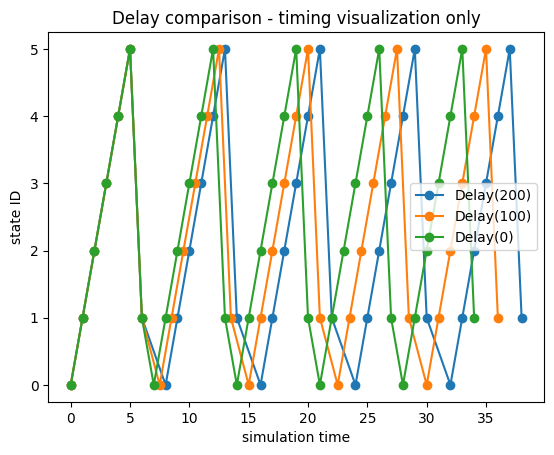

,delay,duration,events
0,200,94.0,84
1,100,88.5,84
2,0,83.0,84


In [ ]:
def delay_variant_stream(delay_value, cycles=12):
    t = []
    state = []
    current = 0.0
    for _ in range(cycles):
        for label in P2_LABELS:
            t.append(current)
            state.append(STATE_ID[label])
            current += 1.0
        current += delay_value / 200.0
    return np.asarray(t), np.asarray(state)


def delay_removal_test(show=True):
    rows = []
    for d in [200, 100, 0]:
        t, s = delay_variant_stream(d)
        rows.append({"delay": d, "duration": t[-1] if len(t) else 0, "events": len(t)})
        if show:
            plt.plot(t[:35], s[:35], marker="o", label=f"Delay({d})")
    if show:
        plt.title("Delay comparison - timing visualization only")
        plt.xlabel("simulation time")
        plt.ylabel("state ID")
        plt.legend()
        plt.show()
    return pd.DataFrame(rows)

if RUN_SUITE_DEMOS:
    display(delay_removal_test())

## 5. P2 Sequence Mutation Detector

Build an exact contextual transition whitelist from the canonical recurrence and detect deliberately injected sequence mutations. This is a structural checker, not an adaptive rewrite of P2.

In [ ]:
def p2_context_whitelist():
    stream = repeated_p2_tokens(4, include_delay=True)
    return set(
        (stream[i - 1], stream[i], stream[i + 1])
        for i in range(1, len(stream) - 1)
    )


def mutate_p2_stream(cycles=20, mutation_rate=0.03, seed=5):
    rng = np.random.default_rng(seed)
    stream = repeated_p2_tokens(cycles, include_delay=True)
    pool = UNIQUE_STATE_LABELS
    mutated_positions = []
    for i in range(1, len(stream) - 1):
        if rng.random() < mutation_rate:
            alternatives = [x for x in pool if x != stream[i]]
            stream[i] = rng.choice(alternatives)
            mutated_positions.append(i)
    return stream, mutated_positions


def detect_p2_mutations(stream):
    whitelist = p2_context_whitelist()
    flagged = []
    for i in range(1, len(stream) - 1):
        triple = (stream[i - 1], stream[i], stream[i + 1])
        if triple not in whitelist:
            flagged.append((i, triple))
    return flagged

if RUN_SUITE_DEMOS:
    mut_stream, true_mut = mutate_p2_stream()
    flags = detect_p2_mutations(mut_stream)
    print("injected positions:", true_mut[:20])
    print("flagged contexts:", flags[:20])

injected positions: [30, 31, 48, 87, 111, 127, 158]
flagged contexts: [(29, ('2,1', '1,0', np.str_('1,0'))), (30, ('1,0', np.str_('1,0'), np.str_('2,1'))), (31, (np.str_('1,0'), np.str_('2,1'), '3,3')), (32, (np.str_('2,1'), '3,3', '0,0')), (47, ('0,0', 'Delay(200)', np.str_('0,1'))), (48, ('Delay(200)', np.str_('0,1'), '0,0')), (49, (np.str_('0,1'), '0,0', '0,1')), (86, ('1,0', '0,0', np.str_('1,0'))), (87, ('0,0', np.str_('1,0'), '3,3')), (88, (np.str_('1,0'), '3,3', '0,0')), (110, ('1,0', '0,0', np.str_('2,1'))), (111, ('0,0', np.str_('2,1'), '3,3')), (112, (np.str_('2,1'), '3,3', '0,0')), (126, ('1,0', '0,0', np.str_('0,0'))), (127, ('0,0', np.str_('0,0'), '3,3')), (128, (np.str_('0,0'), '3,3', '0,0')), (157, ('2,1', '1,0', np.str_('2,1'))), (158, ('1,0', np.str_('2,1'), 'Delay(200)'))]


## 6. Missing-State Reconstruction

Infer a removed middle state from the surrounding `(previous, next)` pair learned from repeated exact cycles. Ambiguous cases are returned as multiple candidates rather than guessed.

In [ ]:
def missing_state_rules(cycles=100):
    stream = repeated_p2_tokens(cycles, include_delay=True)
    rules = defaultdict(Counter)
    for i in range(1, len(stream) - 1):
        rules[(stream[i - 1], stream[i + 1])][stream[i]] += 1
    return rules


def reconstruct_missing_state(previous, next_state, rules=None):
    rules = missing_state_rules() if rules is None else rules
    options = rules.get((previous, next_state), Counter())
    if not options:
        return []
    best = max(options.values())
    return [state for state, count in options.items() if count == best]

if RUN_SUITE_DEMOS:
    rules = missing_state_rules()
    tests = [("0,0", "1,2"), ("2,1", "0,0"), ("1,0", DELAY_TOKEN)]
    for a, b in tests:
        print(a, "?", b, "->", reconstruct_missing_state(a, b, rules))

0,0 ? 1,2 -> ['0,1']
2,1 ? 0,0 -> ['1,0']
1,0 ? Delay(200) -> ['0,0']


## 7. Zero-Return Failure Simulation

Compare the canonical final return to `0,0` with a deliberately broken simulation sequence. The failure case is an artificial diagnostic perturbation.

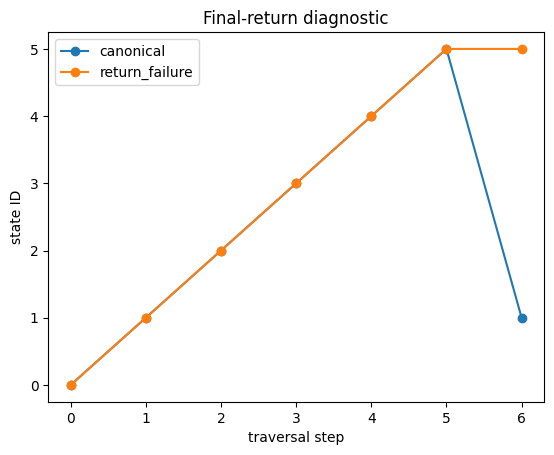

,case,final_state,returned_to_0_0,unique_states
0,canonical,"0,0",True,6
1,return_failure,"1,0",False,6


In [ ]:
def zero_return_failure_test(show=True):
    valid = P2_LABELS.copy()
    failed = P2_LABELS.copy()
    failed[-1] = "1,0"  # deliberate noncanonical perturbation
    rows = []
    for name, seq in [("canonical", valid), ("return_failure", failed)]:
        rows.append({
            "case": name,
            "final_state": seq[-1],
            "returned_to_0_0": seq[-1] == "0,0",
            "unique_states": len(set(seq)),
        })
    if show:
        for name, seq in [("canonical", valid), ("return_failure", failed)]:
            y = [STATE_ID.get(s, -1) for s in seq]
            plt.plot(range(len(seq)), y, marker="o", label=name)
        plt.title("Final-return diagnostic")
        plt.xlabel("traversal step")
        plt.ylabel("state ID")
        plt.legend()
        plt.show()
    return pd.DataFrame(rows)

if RUN_SUITE_DEMOS:
    display(zero_return_failure_test())

## 8. `0,0` Context Classifier

Classify the two occurrences of `0,0` from surrounding traversal context rather than assigning two different coordinates.

In [ ]:
def zero_context_dataset(cycles=200):
    stream = repeated_p2_tokens(cycles, include_delay=True)
    rows = []
    for i in range(1, len(stream) - 1):
        if stream[i] != "0,0":
            continue
        prev, nxt = stream[i - 1], stream[i + 1]
        role = "reference_after_entry" if prev == "3,3" else "return_condition"
        rows.append((prev, nxt, role))
    return pd.DataFrame(rows, columns=["previous", "next", "role"])


def zero_context_classifier(seed=8):
    df = zero_context_dataset()
    X_cat = df[["previous", "next"]]
    y = df["role"].to_numpy()
    enc = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
    X = enc.fit_transform(X_cat)
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(df))
    split = int(0.7 * len(df))
    train, test = idx[:split], idx[split:]
    clf = DecisionTreeClassifier(max_depth=3, random_state=seed)
    clf.fit(X[train], y[train])
    pred = clf.predict(X[test])
    return accuracy_score(y[test], pred), clf, enc, df

if RUN_SUITE_DEMOS:
    acc, _, _, df0 = zero_context_classifier()
    print("context classification accuracy:", acc)
    display(df0.head())

context classification accuracy: 1.0


,previous,next,role
0,"3,3","0,1",reference_after_entry
1,"1,0",Delay(200),return_condition
2,"3,3","0,1",reference_after_entry
3,"1,0",Delay(200),return_condition
4,"3,3","0,1",reference_after_entry


## 9. EchoLift / RosenEcho Collision

Run forward and reverse traversal positions simultaneously with adjustable start offsets and record where both occupy the same coordinate at the same simulation step.

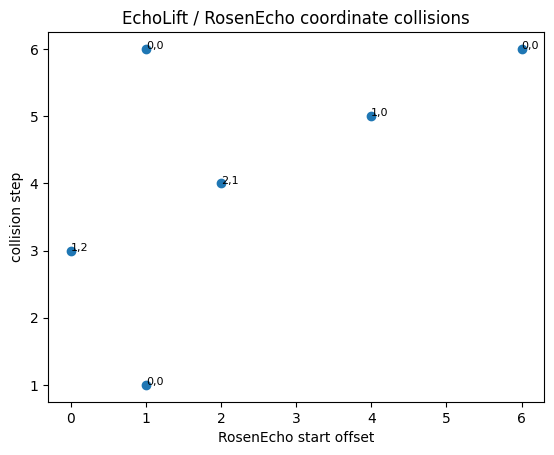

,reverse_start_offset,simulation_step,collision_state
0,0,3,"1,2"
1,1,1,"0,0"
2,1,6,"0,0"
3,2,4,"2,1"
4,4,5,"1,0"
5,6,6,"0,0"


In [ ]:
def echolift_rosenecho_collisions(max_offset=12, show=True):
    forward = P2_LABELS
    reverse = list(reversed(P2_LABELS))
    rows = []
    for offset in range(max_offset + 1):
        for t in range(max(len(forward), offset + len(reverse))):
            a = forward[t] if 0 <= t < len(forward) else None
            j = t - offset
            b = reverse[j] if 0 <= j < len(reverse) else None
            if a is not None and b is not None and a == b:
                rows.append((offset, t, a))
    df = pd.DataFrame(rows, columns=["reverse_start_offset", "simulation_step", "collision_state"])
    if show and len(df):
        plt.scatter(df["reverse_start_offset"], df["simulation_step"])
        for _, r in df.iterrows():
            plt.text(r["reverse_start_offset"], r["simulation_step"], r["collision_state"], fontsize=8)
        plt.xlabel("RosenEcho start offset")
        plt.ylabel("collision step")
        plt.title("EchoLift / RosenEcho coordinate collisions")
        plt.show()
    return df

if RUN_SUITE_DEMOS:
    display(echolift_rosenecho_collisions())

## 10. Traversal Phase Portrait

Interpolate between discrete P2 coordinates only for visualization. The canonical kernel remains discrete; the interpolated curve is not a replacement for it.

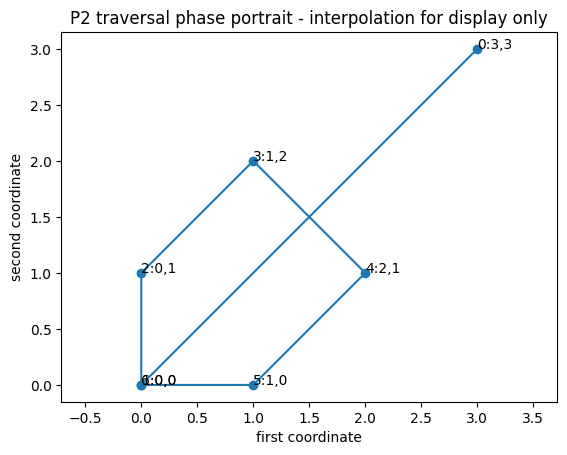

In [ ]:
def traversal_phase_portrait(points_per_segment=50, show=True):
    xy = p2_xy_array()
    path = []
    for a, b in zip(xy[:-1], xy[1:]):
        u = np.linspace(0, 1, points_per_segment, endpoint=False)
        path.append(a[None, :] * (1 - u[:, None]) + b[None, :] * u[:, None])
    path.append(xy[-1][None, :])
    path = np.vstack(path)
    if show:
        plt.plot(path[:, 0], path[:, 1])
        plt.scatter(xy[:, 0], xy[:, 1])
        for i, (x, y) in enumerate(xy):
            plt.text(x, y, f"{i}:{int(x)},{int(y)}")
        plt.axis("equal")
        plt.xlabel("first coordinate")
        plt.ylabel("second coordinate")
        plt.title("P2 traversal phase portrait - interpolation for display only")
        plt.show()
    return path

if RUN_SUITE_DEMOS:
    traversal_phase_portrait()

## 11. P2 Recurrence Spectrogram

Encode the recurring state sequence as integer symbols and inspect the resulting spectrogram. This is an information/signal representation, not a thermodynamic claim.

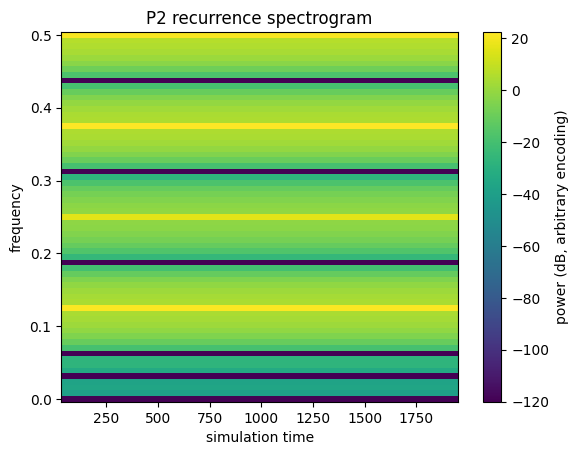

In [ ]:
def p2_recurrence_spectrogram(cycles=250, fs=1.0, show=True):
    x = state_scalar_stream(cycles=cycles, include_delay=True)
    nperseg = min(128, max(16, len(x) // 8))
    f, t, Sxx = signal.spectrogram(x - x.mean(), fs=fs, nperseg=nperseg, noverlap=nperseg // 2)
    if show:
        plt.pcolormesh(t, f, 10 * np.log10(Sxx + 1e-12), shading="auto")
        plt.xlabel("simulation time")
        plt.ylabel("frequency")
        plt.title("P2 recurrence spectrogram")
        plt.colorbar(label="power (dB, arbitrary encoding)")
        plt.show()
    return f, t, Sxx

if RUN_SUITE_DEMOS:
    p2_recurrence_spectrogram()

## 12. Tensor Fingerprint

Create a reproducible geometric fingerprint from transition lengths, turning angles, closure, and recurrence length. Compare exact and perturbed traversals by fingerprint distance.

In [ ]:
def tensor_fingerprint(sequence=CANONICAL_P2):
    pts = np.asarray(sequence, dtype=float)
    diffs = np.diff(pts, axis=0)
    lengths = np.linalg.norm(diffs, axis=1)
    angles = []
    for a, b in zip(diffs[:-1], diffs[1:]):
        denom = np.linalg.norm(a) * np.linalg.norm(b)
        if denom == 0:
            angles.append(0.0)
        else:
            angles.append(float(np.arccos(np.clip(np.dot(a, b) / denom, -1, 1))))
    closure = float(np.linalg.norm(pts[-1] - np.array([0.0, 0.0])))
    return np.concatenate([lengths, np.asarray(angles), [closure, len(sequence)]])


def tensor_fingerprint_test(seed=12, noise=0.15):
    rng = np.random.default_rng(seed)
    ref = tensor_fingerprint()
    perturbed = np.asarray(CANONICAL_P2, dtype=float)
    perturbed[3] += rng.normal(scale=noise, size=2)
    alt = tensor_fingerprint(perturbed)
    return pd.DataFrame([
        {"case": "canonical", "distance_from_reference": 0.0},
        {"case": "perturbed", "distance_from_reference": float(np.linalg.norm(ref - alt))},
    ])

if RUN_SUITE_DEMOS:
    display(tensor_fingerprint_test())

,case,distance_from_reference
0,canonical,0.000000
1,perturbed,0.241026


## 13. P3 Dimensional Survival Test

Use a simulation embedding of the unchanged P2 sequence in increasingly high dimensions, apply distance-preserving random rotations, project to 3D, and measure how well pairwise geometry survives the projection.

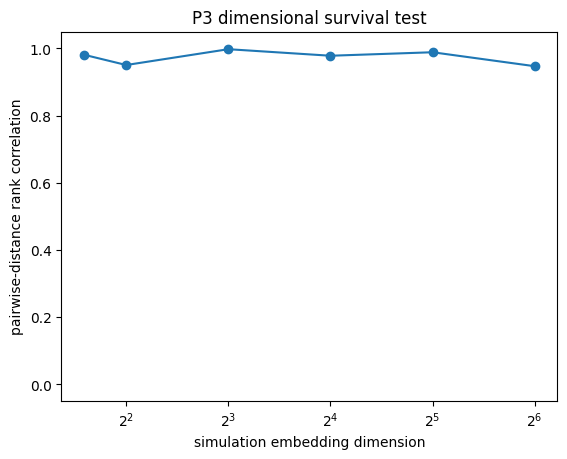

,embedding_dim,pairwise_geometry_spearman
0,3,0.980984
1,4,0.950293
2,8,0.997403
3,16,0.977922
4,32,0.988312
5,64,0.946753


In [ ]:
def _p3_sim_embedding(dim, seed=13):
    xy = p2_xy_array()
    step = np.arange(len(xy), dtype=float)
    feats = [xy[:, 0], xy[:, 1], xy.sum(1), xy[:, 0] - xy[:, 1], np.linalg.norm(xy, axis=1)]
    k = 1
    while len(feats) < dim:
        feats.append(np.sin(k * (step + 1) / 2.0) + np.cos((k + 1) * (xy[:, 0] + 1) / 3.0))
        k += 1
    X = np.column_stack(feats[:dim])
    rng = np.random.default_rng(seed + dim)
    Q, _ = np.linalg.qr(rng.normal(size=(dim, dim)))
    return X @ Q


def p3_dimensional_survival(dimensions=(3, 4, 8, 16, 32, 64), show=True):
    rows = []
    for dim in dimensions:
        X = _p3_sim_embedding(dim)
        d_full = pdist(X)
        Y = PCA(n_components=min(3, dim, len(X) - 1)).fit_transform(X)
        d_proj = pdist(Y)
        rho = stats.spearmanr(d_full, d_proj).statistic
        rows.append((dim, rho))
    df = pd.DataFrame(rows, columns=["embedding_dim", "pairwise_geometry_spearman"])
    if show:
        plt.plot(df.embedding_dim, df.pairwise_geometry_spearman, marker="o")
        plt.xscale("log", base=2)
        plt.ylim(-0.05, 1.05)
        plt.xlabel("simulation embedding dimension")
        plt.ylabel("pairwise-distance rank correlation")
        plt.title("P3 dimensional survival test")
        plt.show()
    return df

if RUN_SUITE_DEMOS:
    display(p3_dimensional_survival())

## 14. P3 Axis Failure

Remove simulated embedding axes one at a time or in groups and measure how much of the full embedding's pairwise geometry remains. Axis coordinates are visualization features, not canonical P3 coordinates.

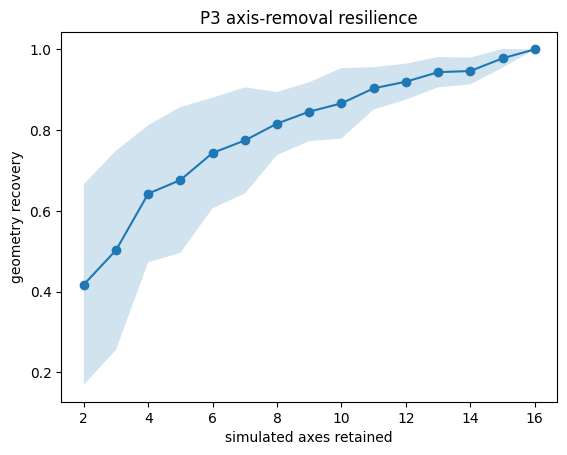

,axes_retained,mean_geometry_recovery,std
0,2,0.417506,0.248651
1,3,0.502649,0.246446
2,4,0.642623,0.169829
3,5,0.676442,0.180758
4,6,0.743636,0.136883
5,7,0.774442,0.131453
6,8,0.816260,0.078121
7,9,0.845766,0.073077
8,10,0.866390,0.087315
9,11,0.903584,0.052377


In [ ]:
def p3_axis_failure(dim=16, trials=50, seed=14, show=True):
    X = _p3_sim_embedding(dim, seed=seed)
    d_ref = pdist(X)
    rng = np.random.default_rng(seed)
    rows = []
    for retained in range(2, dim + 1):
        vals = []
        for _ in range(trials):
            cols = rng.choice(dim, size=retained, replace=False)
            rho = stats.spearmanr(d_ref, pdist(X[:, cols])).statistic
            vals.append(rho)
        rows.append((retained, float(np.mean(vals)), float(np.std(vals))))
    df = pd.DataFrame(rows, columns=["axes_retained", "mean_geometry_recovery", "std"])
    if show:
        plt.plot(df.axes_retained, df.mean_geometry_recovery, marker="o")
        plt.fill_between(df.axes_retained, df.mean_geometry_recovery - df["std"], df.mean_geometry_recovery + df["std"], alpha=0.2)
        plt.xlabel("simulated axes retained")
        plt.ylabel("geometry recovery")
        plt.title("P3 axis-removal resilience")
        plt.show()
    return df

if RUN_SUITE_DEMOS:
    display(p3_axis_failure())

## 15. P3 Phase-Locking Map

Use the standard circular order parameter only as a **sonification/simulation alignment metric** across synthetic P3 voice phases. This does not define canonical P3 phase mathematics.

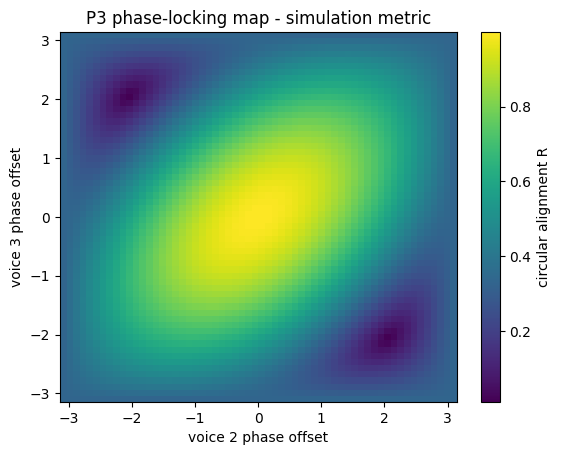

In [ ]:
def p3_phase_locking_map(grid=60, show=True):
    phi = np.linspace(-np.pi, np.pi, grid)
    R = np.zeros((grid, grid))
    for i, a in enumerate(phi):
        for j, b in enumerate(phi):
            phases = np.array([0.0, a, b])
            R[i, j] = abs(np.mean(np.exp(1j * phases)))
    if show:
        plt.imshow(R, origin="lower", extent=[-np.pi, np.pi, -np.pi, np.pi], aspect="auto")
        plt.xlabel("voice 2 phase offset")
        plt.ylabel("voice 3 phase offset")
        plt.title("P3 phase-locking map - simulation metric")
        plt.colorbar(label="circular alignment R")
        plt.show()
    return phi, R

if RUN_SUITE_DEMOS:
    p3_phase_locking_map()

## 16. Resonance Reinforcement Heatmap

Sweep a simulation-only reinforcement control against phase mismatch and measure correlation with a reference P2-derived waveform. The heatmap is a sonification/signal experiment, not a canonical resonance law.

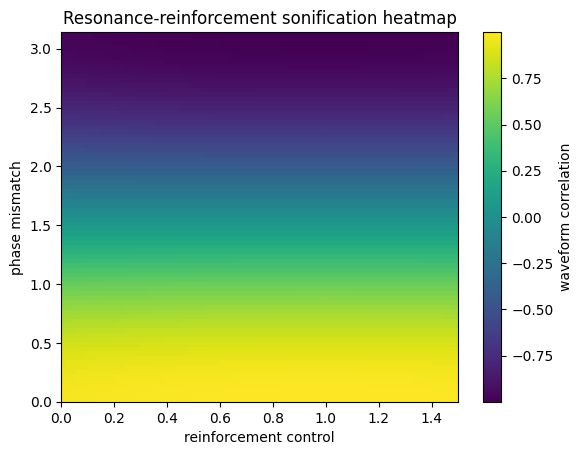

In [ ]:
def resonance_reinforcement_heatmap(n=80, show=True):
    r_vals = np.linspace(0, 1.5, n)
    phase_vals = np.linspace(0, np.pi, n)
    t = np.linspace(0, 8 * np.pi, 1200)
    base = np.sin(t) + 0.25 * np.sin(2 * t)
    Z = np.zeros((n, n))
    for i, phase in enumerate(phase_vals):
        for j, r in enumerate(r_vals):
            test = np.sin(t + phase) + r * 0.25 * np.sin(2 * t + phase)
            Z[i, j] = np.corrcoef(base, test)[0, 1]
    if show:
        plt.imshow(Z, origin="lower", extent=[r_vals.min(), r_vals.max(), phase_vals.min(), phase_vals.max()], aspect="auto")
        plt.xlabel("reinforcement control")
        plt.ylabel("phase mismatch")
        plt.title("Resonance-reinforcement sonification heatmap")
        plt.colorbar(label="waveform correlation")
        plt.show()
    return r_vals, phase_vals, Z

if RUN_SUITE_DEMOS:
    resonance_reinforcement_heatmap()

## 17. P3 Nested Sphere

Place unchanged copies of the P2 traversal on nested spherical shells as a spatial visualization of nested dimensional embedding. Shell radius is a visualization coordinate only.

In [ ]:
def p3_nested_sphere(shells=5, show=True):
    rows = []
    for shell in range(1, shells + 1):
        r = float(shell)
        for step, (x, y) in enumerate(CANONICAL_P2):
            theta = 2 * np.pi * step / len(CANONICAL_P2)
            phi = np.pi * (0.2 + 0.6 * (x + y) / 6.0)
            X = r * np.sin(phi) * np.cos(theta)
            Y = r * np.sin(phi) * np.sin(theta)
            Z = r * np.cos(phi)
            rows.append((shell, step, f"{x},{y}", X, Y, Z))
    df = pd.DataFrame(rows, columns=["shell", "step", "state", "x", "y", "z"])
    if show:
        fig = go.Figure()
        for shell in range(1, shells + 1):
            s = df[df.shell == shell]
            fig.add_trace(go.Scatter3d(x=s.x, y=s.y, z=s.z, mode="lines+markers", name=f"shell {shell}"))
        fig.update_layout(title="P3 nested-sphere visualization")
        fig.show()
    return df

if RUN_SUITE_DEMOS:
    p3_nested_sphere()

## 18. Echo Meridian + P3 Combined Geometry

Display the Echo Meridian as one fixed reference axis while rotating synthetic P3 embedding geometry around it. The z-axis is only the coordinate system chosen for the visualization; it is not a redefinition of `M_E`.

In [ ]:
def echo_meridian_p3_geometry(angle=0.7, shells=4, show=True):
    df = p3_nested_sphere(shells=shells, show=False).copy()
    c, s = np.cos(angle), np.sin(angle)
    x = c * df["x"].to_numpy() - s * df["y"].to_numpy()
    y = s * df["x"].to_numpy() + c * df["y"].to_numpy()
    df["x_rot"], df["y_rot"] = x, y
    if show:
        fig = go.Figure()
        for shell in sorted(df.shell.unique()):
            q = df[df.shell == shell]
            fig.add_trace(go.Scatter3d(x=q.x_rot, y=q.y_rot, z=q.z, mode="lines+markers", name=f"P3 shell {shell}"))
        fig.add_trace(go.Scatter3d(x=[0,0], y=[0,0], z=[-shells-1, shells+1], mode="lines", name="Echo Meridian display axis"))
        fig.update_layout(title="Echo Meridian reference axis with rotated P3 visualization")
        fig.show()
    return df

if RUN_SUITE_DEMOS:
    echo_meridian_p3_geometry()

## 19. Resonance Recoil Layer Formation

A structural toy model of the disclosed sequence: coherence convergence toward a selectable threshold followed by differentiation into nested radial layers. Parameters below are visualization controls, not a canonical cosmological solver.

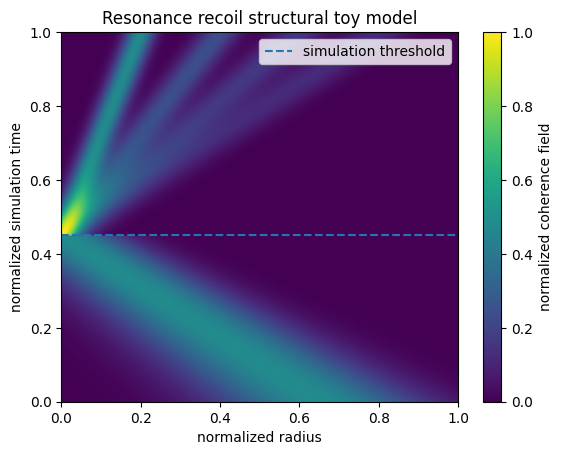

In [ ]:
def resonance_recoil_toy(nr=240, nt=180, threshold_time=0.45, layers=4, show=True):
    r = np.linspace(0, 1, nr)
    t = np.linspace(0, 1, nt)
    C = np.zeros((nt, nr))
    for i, ti in enumerate(t):
        if ti <= threshold_time:
            center = 0.65 * (1 - ti / max(threshold_time, 1e-9))
            width = 0.10 + 0.08 * (1 - ti / max(threshold_time, 1e-9))
            C[i] = np.exp(-0.5 * ((r - center) / width) ** 2)
        else:
            tau = (ti - threshold_time) / max(1 - threshold_time, 1e-9)
            for k in range(layers):
                center = (k + 1) / (layers + 1) * tau
                width = 0.025 + 0.01 * k
                C[i] += np.exp(-0.5 * ((r - center) / width) ** 2) / (k + 1)
    C /= max(C.max(), 1e-12)
    if show:
        plt.imshow(C, origin="lower", aspect="auto", extent=[r.min(), r.max(), t.min(), t.max()])
        plt.axhline(threshold_time, linestyle="--", label="simulation threshold")
        plt.xlabel("normalized radius")
        plt.ylabel("normalized simulation time")
        plt.title("Resonance recoil structural toy model")
        plt.colorbar(label="normalized coherence field")
        plt.legend()
        plt.show()
    return r, t, C

if RUN_SUITE_DEMOS:
    resonance_recoil_toy()

## 20. LDCT Emergence

Create a synthetic spatial network in which long-distance links form from a user-chosen coherence-similarity criterion rather than Euclidean nearness. The link rule is a toy criterion, not the undisclosed physical law of LDCT.

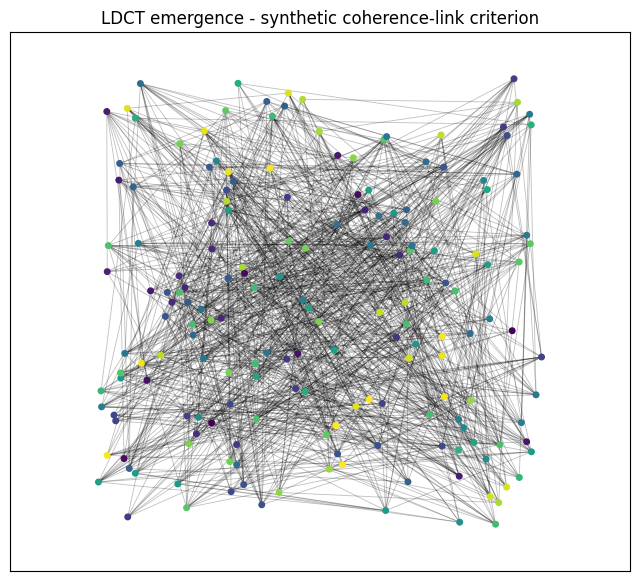

nodes: 180 edges: 889


In [ ]:
def ldct_emergence(n=180, coherence_threshold=0.04, seed=20, show=True):
    rng = np.random.default_rng(seed)
    pos = rng.random((n, 2))
    coherence = rng.random(n)
    G = nx.Graph()
    G.add_nodes_from(range(n))
    for i in range(n):
        G.nodes[i]["pos"] = tuple(pos[i])
        G.nodes[i]["coherence"] = float(coherence[i])
    for i in range(n):
        for j in range(i + 1, n):
            similarity = abs(coherence[i] - coherence[j])
            distance = np.linalg.norm(pos[i] - pos[j])
            if similarity < coherence_threshold and distance > 0.35:
                G.add_edge(i, j, distance=float(distance), similarity=float(similarity))
    if show:
        plt.figure(figsize=(8, 7))
        nx.draw_networkx_edges(G, {i: pos[i] for i in range(n)}, alpha=0.25, width=0.6)
        plt.scatter(pos[:, 0], pos[:, 1], s=16, c=coherence)
        plt.title("LDCT emergence - synthetic coherence-link criterion")
        plt.axis("equal")
        plt.show()
    return G

if RUN_SUITE_DEMOS:
    G_ldct = ldct_emergence()
    print("nodes:", G_ldct.number_of_nodes(), "edges:", G_ldct.number_of_edges())

## 21. LDCT Cut Test

Apply different removal strategies to the synthetic LDCT network and measure the largest remaining connected component. This tests the toy network created above, not a physical LDCT implementation.

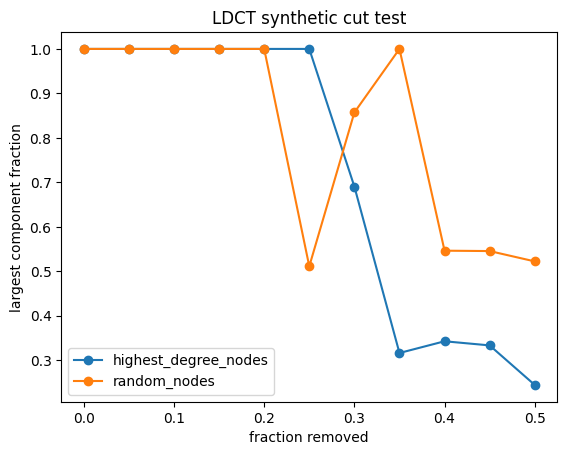

,strategy,fraction_removed,largest_component_fraction
0,random_nodes,0.00,1.000000
1,highest_degree_nodes,0.00,1.000000
2,random_nodes,0.05,1.000000
3,highest_degree_nodes,0.05,1.000000
4,random_nodes,0.10,1.000000
5,highest_degree_nodes,0.10,1.000000
6,random_nodes,0.15,1.000000
7,highest_degree_nodes,0.15,1.000000
8,random_nodes,0.20,1.000000
9,highest_degree_nodes,0.20,1.000000


In [ ]:
def _largest_component_fraction(G):
    if G.number_of_nodes() == 0:
        return 0.0
    if G.number_of_edges() == 0:
        return 1.0 / G.number_of_nodes()
    return max(len(c) for c in nx.connected_components(G)) / G.number_of_nodes()


def ldct_cut_test(G=None, fractions=np.linspace(0, 0.5, 11), seed=21, show=True):
    if G is None:
        G = ldct_emergence(show=False)
    rng = np.random.default_rng(seed)
    rows = []
    nodes = list(G.nodes())
    degrees = dict(G.degree())
    for frac in fractions:
        k = int(round(frac * len(nodes)))
        for strategy in ["random_nodes", "highest_degree_nodes"]:
            H = G.copy()
            if k:
                if strategy == "random_nodes":
                    remove = rng.choice(nodes, size=min(k, len(nodes)), replace=False).tolist()
                else:
                    remove = sorted(nodes, key=lambda n: degrees[n], reverse=True)[:k]
                H.remove_nodes_from(remove)
            rows.append((strategy, frac, _largest_component_fraction(H)))
    df = pd.DataFrame(rows, columns=["strategy", "fraction_removed", "largest_component_fraction"])
    if show:
        for strategy, q in df.groupby("strategy"):
            plt.plot(q.fraction_removed, q.largest_component_fraction, marker="o", label=strategy)
        plt.xlabel("fraction removed")
        plt.ylabel("largest component fraction")
        plt.title("LDCT synthetic cut test")
        plt.legend()
        plt.show()
    return df

if RUN_SUITE_DEMOS:
    display(ldct_cut_test())

## 22. DiamondFlex Nano-Diamond Ensemble

Represent each simulated nano-diamond node as carrying the same full P2 logic while its current traversal phase may differ. This tests ensemble phase distribution only; it does not change the embedded kernel.

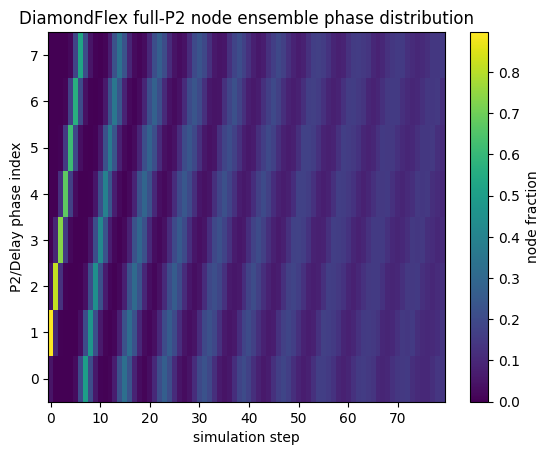

In [ ]:
def diamondflex_ensemble(n_nodes=5000, steps=80, phase_jitter=0.15, seed=22, show=True):
    rng = np.random.default_rng(seed)
    cycle_len = len(P2_CYCLE_TOKENS)
    phase = np.zeros(n_nodes, dtype=int)
    history = []
    for t in range(steps):
        jitter = rng.random(n_nodes) < phase_jitter
        increments = np.ones(n_nodes, dtype=int)
        increments[jitter] = rng.integers(0, 3, size=jitter.sum())
        phase = (phase + increments) % cycle_len
        counts = np.bincount(phase, minlength=cycle_len) / n_nodes
        history.append(counts)
    H = np.vstack(history)
    if show:
        plt.imshow(H.T, aspect="auto", origin="lower")
        plt.xlabel("simulation step")
        plt.ylabel("P2/Delay phase index")
        plt.title("DiamondFlex full-P2 node ensemble phase distribution")
        plt.colorbar(label="node fraction")
        plt.show()
    return H

if RUN_SUITE_DEMOS:
    diamondflex_ensemble()

## 23. DiamondFlex Routing Maze

Compare a shortest-path route with a simulation route that adds an explicit turn penalty. The turn penalty is merely a routing-cost experiment; it is not a canonical DiamondFlex coherence law.

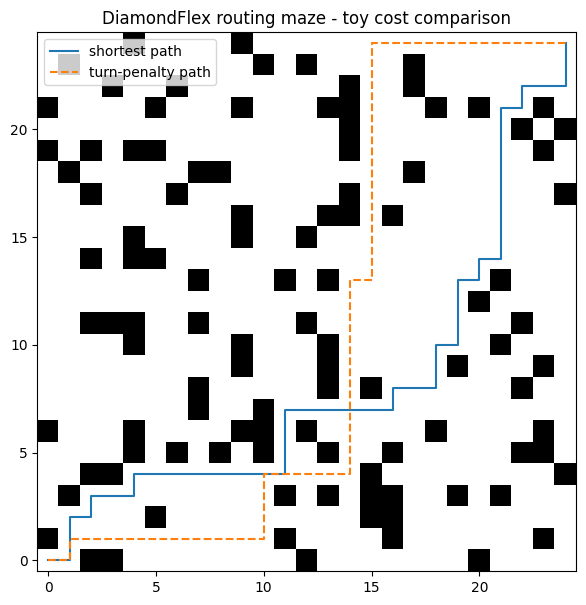

In [ ]:
def diamondflex_routing_maze(size=25, block_fraction=0.20, turn_penalty=0.8, seed=23, show=True):
    rng = np.random.default_rng(seed)
    blocked = rng.random((size, size)) < block_fraction
    blocked[0, 0] = False
    blocked[-1, -1] = False
    G = nx.grid_2d_graph(size, size)
    G.remove_nodes_from([tuple(x) for x in np.argwhere(blocked)])
    start, goal = (0, 0), (size - 1, size - 1)
    if start not in G or goal not in G or not nx.has_path(G, start, goal):
        return diamondflex_routing_maze(size, max(0.05, block_fraction - 0.03), turn_penalty, seed + 1, show)
    shortest = nx.shortest_path(G, start, goal)

    # Expanded state graph: (node, previous_direction) so turns can carry cost.
    H = nx.DiGraph()
    dirs = [(1,0), (-1,0), (0,1), (0,-1)]
    for u in G.nodes:
        for prev in dirs + [(0,0)]:
            H.add_node((u, prev))
    for u, v in G.edges:
        for a, b in [(u, v), (v, u)]:
            d = (b[0] - a[0], b[1] - a[1])
            for prev in dirs + [(0,0)]:
                cost = 1.0 + (turn_penalty if prev != (0,0) and prev != d else 0.0)
                H.add_edge((a, prev), (b, d), weight=cost)
    source = (start, (0,0))
    targets = [(goal, d) for d in dirs]
    lengths = nx.single_source_dijkstra_path_length(H, source, weight="weight")
    reachable_targets = [z for z in targets if z in lengths]
    if not reachable_targets:
        raise RuntimeError("Goal is not reachable in the expanded routing graph.")
    best_target = min(reachable_targets, key=lambda z: lengths[z])
    expanded = nx.shortest_path(H, source, best_target, weight="weight")
    turn_route = [state[0] for state in expanded]

    if show:
        plt.figure(figsize=(7, 7))
        plt.imshow(blocked, origin="lower", cmap="gray_r")
        a = np.array(shortest)
        b = np.array(turn_route)
        plt.plot(a[:, 1], a[:, 0], label="shortest path")
        plt.plot(b[:, 1], b[:, 0], linestyle="--", label="turn-penalty path")
        plt.legend()
        plt.title("DiamondFlex routing maze - toy cost comparison")
        plt.show()
    return {"blocked": blocked, "shortest": shortest, "turn_penalty_route": turn_route}

if RUN_SUITE_DEMOS:
    diamondflex_routing_maze()

## 24. DiamondFlex Defect Propagation

Use a normalized 2D diffusion field as a generic defect-propagation toy model. It does not predict real DiamondFlex transport coefficients.

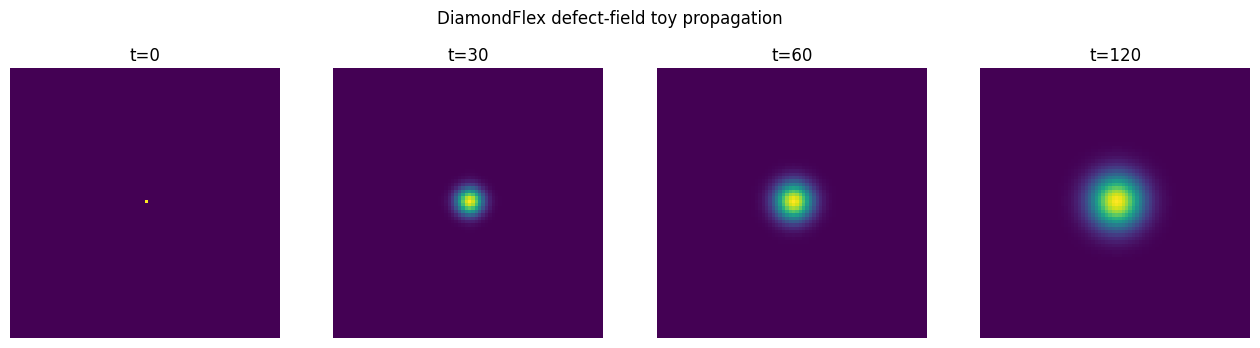

In [ ]:
def diamondflex_defect_propagation(size=80, steps=120, diffusion=0.12, show=True):
    field = np.zeros((size, size), dtype=float)
    field[size // 2, size // 2] = 1.0
    snapshots = {0: field.copy()}
    for t in range(1, steps + 1):
        lap = (
            np.roll(field, 1, 0) + np.roll(field, -1, 0)
            + np.roll(field, 1, 1) + np.roll(field, -1, 1)
            - 4 * field
        )
        field = np.clip(field + diffusion * lap, 0, None)
        if t in [steps // 4, steps // 2, steps]:
            snapshots[t] = field.copy()
    if show:
        fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 4))
        for ax, (t, img) in zip(np.atleast_1d(axes), snapshots.items()):
            ax.imshow(img, origin="lower")
            ax.set_title(f"t={t}")
            ax.axis("off")
        plt.suptitle("DiamondFlex defect-field toy propagation")
        plt.show()
    return snapshots

if RUN_SUITE_DEMOS:
    diamondflex_defect_propagation()

## 25. DiamondFlex Full-P2 Node Synchronization

Give nodes random traversal offsets and apply a simulation-only circular synchronization rule that changes timing phase but never rewrites the local P2 sequence.

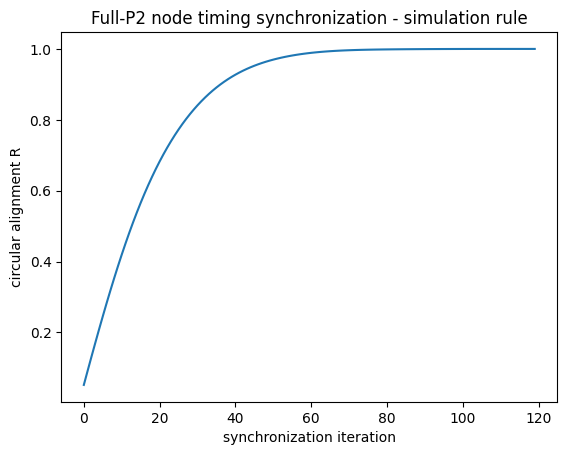

In [ ]:
def diamondflex_p2_synchronization(n_nodes=2000, steps=120, coupling=0.08, seed=25, show=True):
    rng = np.random.default_rng(seed)
    phases = rng.uniform(0, 2 * np.pi, n_nodes)
    order = []
    for _ in range(steps):
        mean_phase = np.angle(np.mean(np.exp(1j * phases)))
        phases += coupling * np.sin(mean_phase - phases)
        phases = np.mod(phases, 2 * np.pi)
        order.append(abs(np.mean(np.exp(1j * phases))))
    if show:
        plt.plot(order)
        plt.xlabel("synchronization iteration")
        plt.ylabel("circular alignment R")
        plt.title("Full-P2 node timing synchronization - simulation rule")
        plt.show()
    return np.asarray(order), phases

if RUN_SUITE_DEMOS:
    diamondflex_p2_synchronization()

## 26. QRTM Phase-Correlation Cloud

Generate bounded oscillatory degrees of freedom, compute instantaneous phase with a Hilbert transform, then map the pairwise phase-locking matrix. These synthetic signals are test inputs, not a replacement for the user's QRTM definitions.

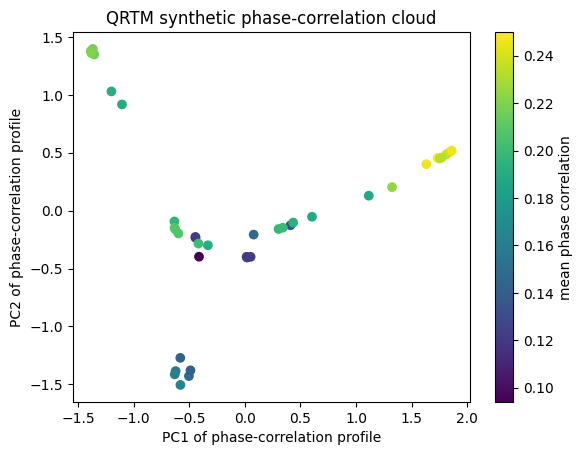

In [ ]:
def qrtm_phase_correlation_cloud(n_signals=40, samples=1800, seed=26, show=True):
    rng = np.random.default_rng(seed)
    t = np.linspace(0, 20, samples)
    signals = []
    for _ in range(n_signals):
        f = rng.uniform(0.7, 1.3)
        phase = rng.uniform(-np.pi, np.pi)
        amp = rng.uniform(0.7, 1.0)
        signals.append(amp * np.sin(2 * np.pi * f * t + phase))
    X = np.asarray(signals)
    phases = np.angle(signal.hilbert(X, axis=1))
    PLV = np.zeros((n_signals, n_signals))
    for i in range(n_signals):
        for j in range(n_signals):
            PLV[i, j] = abs(np.mean(np.exp(1j * (phases[i] - phases[j]))))
    coords = PCA(n_components=2).fit_transform(PLV)
    df = pd.DataFrame(coords, columns=["PC1", "PC2"])
    df["mean_phase_correlation"] = PLV.mean(axis=1)
    if show:
        plt.scatter(df.PC1, df.PC2, c=df.mean_phase_correlation)
        plt.xlabel("PC1 of phase-correlation profile")
        plt.ylabel("PC2 of phase-correlation profile")
        plt.title("QRTM synthetic phase-correlation cloud")
        plt.colorbar(label="mean phase correlation")
        plt.show()
    return X, PLV, df

if RUN_SUITE_DEMOS:
    qrtm_phase_correlation_cloud()

## 27. QRTM Threshold Boundary

No undisclosed canonical intake-threshold values are inserted here. Instead, the notebook exposes explicit **demo thresholds** so you can later replace them with values you choose.

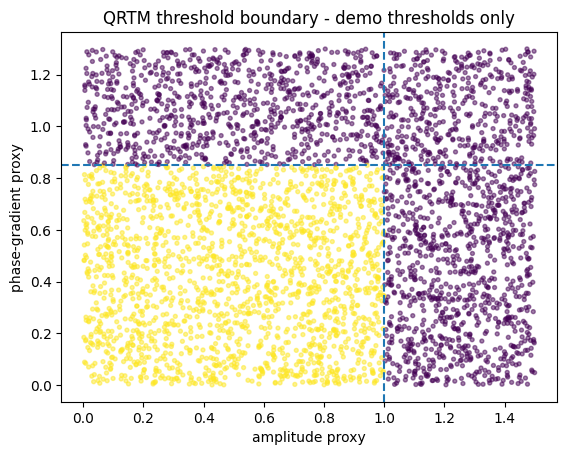

,amplitude_proxy,phase_gradient_proxy,admitted_under_demo_rule
0,1.046604,0.878857,False
1,0.470721,0.429828,True
2,0.181796,1.290094,False
3,0.485387,0.859177,False
4,1.396818,1.041862,False


In [ ]:
def qrtm_threshold_boundary(n=4000, amp_threshold_demo=1.0, gradient_threshold_demo=0.85, seed=27, show=True):
    rng = np.random.default_rng(seed)
    amplitude = rng.uniform(0, 1.5, n)
    phase_gradient = rng.uniform(0, 1.3, n)
    admitted = (amplitude <= amp_threshold_demo) & (phase_gradient <= gradient_threshold_demo)
    df = pd.DataFrame({
        "amplitude_proxy": amplitude,
        "phase_gradient_proxy": phase_gradient,
        "admitted_under_demo_rule": admitted,
    })
    if show:
        plt.scatter(amplitude, phase_gradient, c=admitted.astype(int), s=8, alpha=0.5)
        plt.axvline(amp_threshold_demo, linestyle="--")
        plt.axhline(gradient_threshold_demo, linestyle="--")
        plt.xlabel("amplitude proxy")
        plt.ylabel("phase-gradient proxy")
        plt.title("QRTM threshold boundary - demo thresholds only")
        plt.show()
    return df

if RUN_SUITE_DEMOS:
    display(qrtm_threshold_boundary().head())

## 28. QRTM Spike Injection

Inject controlled spikes into an otherwise bounded sinusoidal test signal and evaluate them against an explicit demo threshold. Spiky signatures remain diagnostic inputs, not admissible baseline QRTM states.

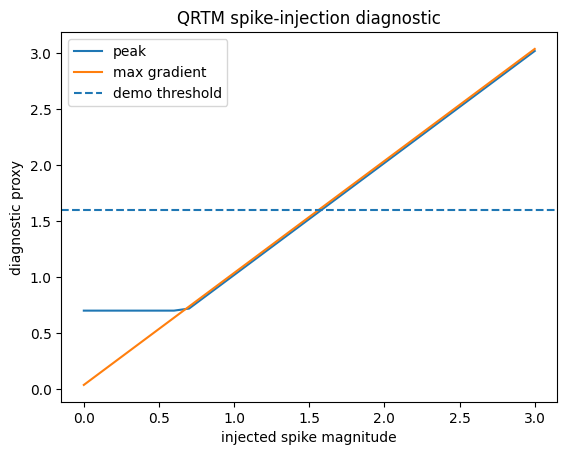

,injected_spike,peak,max_gradient,rejected_under_demo_rule
0,0.0,0.699999,0.036678,False
1,0.1,0.699999,0.136678,False
2,0.2,0.699999,0.236678,False
3,0.3,0.699999,0.336678,False
4,0.4,0.699999,0.436678,False
5,0.5,0.699999,0.536678,False
6,0.6,0.699999,0.636678,False
7,0.7,0.718339,0.736678,False
8,0.8,0.818339,0.836678,False
9,0.9,0.918339,0.936678,False


In [ ]:
def qrtm_spike_injection(spike_sizes=np.linspace(0, 3, 31), threshold_demo=1.6, show=True):
    t = np.linspace(0, 10, 1200)
    base = 0.7 * np.sin(2 * np.pi * t)
    rows = []
    for spike in spike_sizes:
        x = base.copy()
        x[len(x) // 2] += spike
        peak = float(np.max(np.abs(x)))
        grad = float(np.max(np.abs(np.diff(x))))
        proxy = max(peak, grad)
        rows.append((spike, peak, grad, proxy > threshold_demo))
    df = pd.DataFrame(rows, columns=["injected_spike", "peak", "max_gradient", "rejected_under_demo_rule"])
    if show:
        plt.plot(df.injected_spike, df.peak, label="peak")
        plt.plot(df.injected_spike, df.max_gradient, label="max gradient")
        plt.axhline(threshold_demo, linestyle="--", label="demo threshold")
        plt.xlabel("injected spike magnitude")
        plt.ylabel("diagnostic proxy")
        plt.title("QRTM spike-injection diagnostic")
        plt.legend()
        plt.show()
    return df

if RUN_SUITE_DEMOS:
    display(qrtm_spike_injection())

## 29. Wilson Branch-Growth Simulation

Grow a synthetic bucket/branch graph around a fixed P2 core while feeding environmental fragments. This is an architectural visualization, not a claim that these toy routing rules are Wilson's undisclosed implementation.

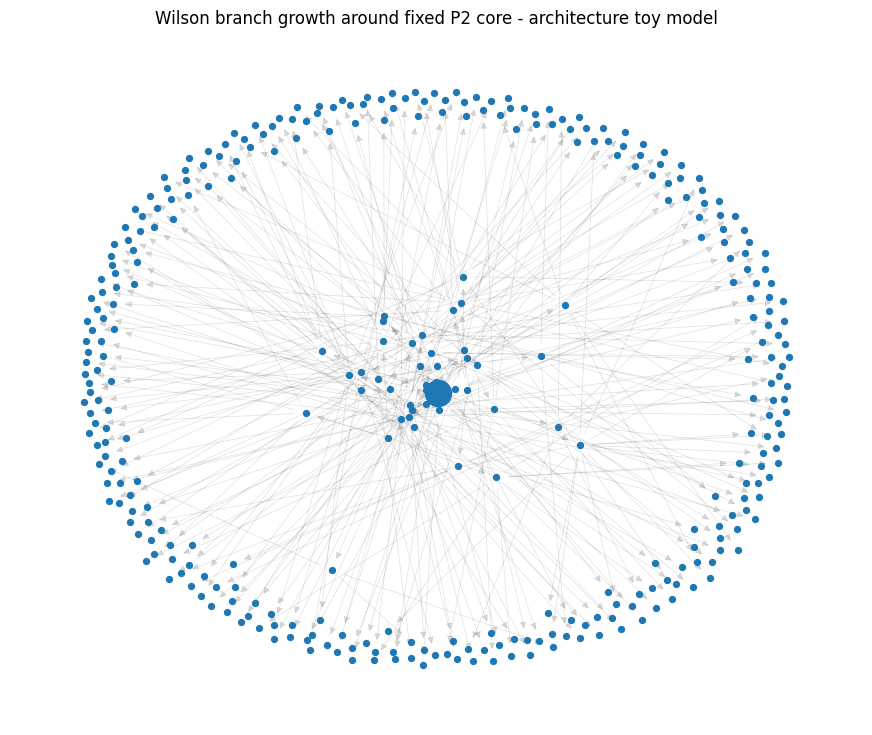

343 342


In [ ]:
def wilson_branch_growth(n_fragments=300, seed=29, show=True):
    rng = np.random.default_rng(seed)
    topics = ["motion", "sound", "temperature", "location", "object", "sequence"]
    G = nx.DiGraph()
    G.add_node("P2_KERNEL", kind="fixed_kernel")
    for topic in topics:
        bucket = f"bucket:{topic}"
        G.add_edge("P2_KERNEL", bucket)
    for i in range(n_fragments):
        topic = rng.choice(topics)
        branch = f"branch:{topic}:{rng.integers(0, 6)}"
        fragment = f"fragment:{i}"
        G.add_edge(f"bucket:{topic}", branch)
        G.add_edge(branch, fragment)
    if show:
        pos = nx.spring_layout(G, seed=seed, k=0.25, iterations=70)
        plt.figure(figsize=(11, 9))
        nx.draw_networkx_edges(G, pos, alpha=0.12, width=0.5)
        nx.draw_networkx_nodes(G, pos, node_size=18)
        nx.draw_networkx_nodes(G, pos, nodelist=["P2_KERNEL"], node_size=350)
        plt.title("Wilson branch growth around fixed P2 core - architecture toy model")
        plt.axis("off")
        plt.show()
    return G

if RUN_SUITE_DEMOS:
    G_wilson = wilson_branch_growth()
    print(G_wilson.number_of_nodes(), G_wilson.number_of_edges())

## 30. Wilson Unresolved Fragment Memory

Store synthetic fragments until enough related context accumulates to resolve them. The resolution count is an explicit demo control.

In [ ]:
def wilson_unresolved_memory(n_events=120, context_needed_demo=3, seed=30):
    rng = np.random.default_rng(seed)
    topics = ["A", "B", "C", "D", "E"]
    unresolved = defaultdict(list)
    resolved = []
    timeline = []
    for i in range(n_events):
        topic = rng.choice(topics)
        fragment = f"f{i}:{topic}"
        unresolved[topic].append(fragment)
        if len(unresolved[topic]) >= context_needed_demo:
            resolved.extend(unresolved[topic])
            unresolved[topic] = []
        timeline.append({
            "event": i,
            "topic": topic,
            "resolved_total": len(resolved),
            "unresolved_total": sum(len(v) for v in unresolved.values()),
        })
    return pd.DataFrame(timeline), unresolved, resolved

if RUN_SUITE_DEMOS:
    timeline, unresolved, resolved = wilson_unresolved_memory()
    display(timeline.tail())

,event,topic,resolved_total,unresolved_total
115,115,D,111,5
116,116,C,114,3
117,117,B,114,4
118,118,C,114,5
119,119,C,114,6


## 31. Wilson False-Context Rejection

Compare candidate contexts with a toy structural-overlap score and reject low-scoring matches. The scoring formula is explicitly a simulation convenience, not a canonical Wilson rule.

In [ ]:
def wilson_false_context_rejection(query_tokens, candidates, threshold_demo=0.5):
    q = set(query_tokens)
    rows = []
    for name, tokens in candidates.items():
        s = set(tokens)
        union = q | s
        score = len(q & s) / len(union) if union else 0.0
        rows.append((name, score, score >= threshold_demo))
    return pd.DataFrame(rows, columns=["candidate", "toy_overlap_score", "accepted_under_demo_rule"]).sort_values("toy_overlap_score", ascending=False)

if RUN_SUITE_DEMOS:
    demo_candidates = {
        "context_A": ["motion", "object", "left"],
        "context_B": ["temperature", "warm", "room"],
        "context_C": ["motion", "object", "right"],
    }
    display(wilson_false_context_rejection(["motion", "object", "left"], demo_candidates))

,candidate,toy_overlap_score,accepted_under_demo_rule
0,context_A,1.0,True
2,context_C,0.5,True
1,context_B,0.0,False


## 32. Kernel vs Phenotype Growth

Track a fixed hash of the P2 kernel while a synthetic higher-level graph grows over time. The central kernel representation never changes.

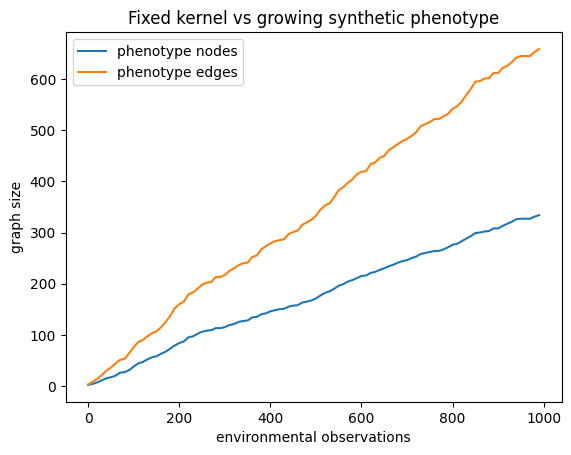

,observation,phenotype_nodes,phenotype_edges,kernel_sha256
95,950,327,645,e79eeab45fa25ae9663f40b7107248fa490d4bfb32fad2...
96,960,327,645,e79eeab45fa25ae9663f40b7107248fa490d4bfb32fad2...
97,970,327,645,e79eeab45fa25ae9663f40b7107248fa490d4bfb32fad2...
98,980,331,653,e79eeab45fa25ae9663f40b7107248fa490d4bfb32fad2...
99,990,334,659,e79eeab45fa25ae9663f40b7107248fa490d4bfb32fad2...


In [ ]:
def _kernel_hash():
    payload = repr(CANONICAL_P2).encode("utf-8")
    return hashlib.sha256(payload).hexdigest()


def kernel_vs_phenotype_growth(observations=1000, seed=32, show=True):
    rng = np.random.default_rng(seed)
    kernel_hash = _kernel_hash()
    nodes = 1
    edges = 0
    rows = []
    for t in range(observations):
        if rng.random() < 0.35:
            nodes += 1
            edges += int(rng.integers(1, 4))
        if t % max(1, observations // 100) == 0:
            rows.append((t, nodes, edges, kernel_hash))
    df = pd.DataFrame(rows, columns=["observation", "phenotype_nodes", "phenotype_edges", "kernel_sha256"])
    if show:
        plt.plot(df.observation, df.phenotype_nodes, label="phenotype nodes")
        plt.plot(df.observation, df.phenotype_edges, label="phenotype edges")
        plt.xlabel("environmental observations")
        plt.ylabel("graph size")
        plt.title("Fixed kernel vs growing synthetic phenotype")
        plt.legend()
        plt.show()
    return df

if RUN_SUITE_DEMOS:
    display(kernel_vs_phenotype_growth().tail())

## 33. Artificial-Gravity Ring Coupling

Use a generic coupled-oscillator surrogate to study disturbance propagation across concentric rings. This is **not** an equation for RIPAS or a physical gravity claim; it is an engineering toy model for ring-to-ring coupling behavior.

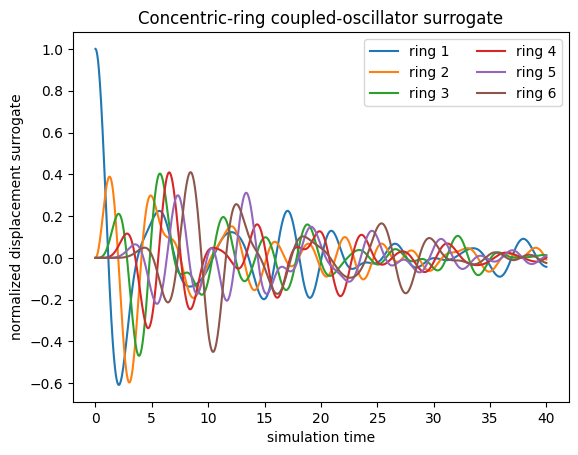

In [ ]:
def artificial_gravity_ring_coupling(n_rings=6, coupling=1.2, damping=0.12, omega=1.0, t_end=40, show=True):
    def rhs(t, y):
        x = y[:n_rings]
        v = y[n_rings:]
        lap = np.zeros(n_rings)
        for i in range(n_rings):
            if i > 0:
                lap[i] += x[i - 1] - x[i]
            if i < n_rings - 1:
                lap[i] += x[i + 1] - x[i]
        a = -damping * v - omega**2 * x + coupling * lap
        return np.concatenate([v, a])

    y0 = np.zeros(2 * n_rings)
    y0[0] = 1.0
    t_eval = np.linspace(0, t_end, 1200)
    sol = solve_ivp(rhs, (0, t_end), y0, t_eval=t_eval, rtol=1e-7, atol=1e-9)
    X = sol.y[:n_rings]
    if show:
        for i in range(n_rings):
            plt.plot(sol.t, X[i], label=f"ring {i+1}")
        plt.xlabel("simulation time")
        plt.ylabel("normalized displacement surrogate")
        plt.title("Concentric-ring coupled-oscillator surrogate")
        plt.legend(ncol=2)
        plt.show()
    return sol.t, X

if RUN_SUITE_DEMOS:
    artificial_gravity_ring_coupling()

## 34. Habitat Layer Propagation

Use the canonical DiamondFlex layer order as a seven-node coupled chain and inject a normalized exterior impulse. Coefficients are generic simulation controls, not measured material constants.

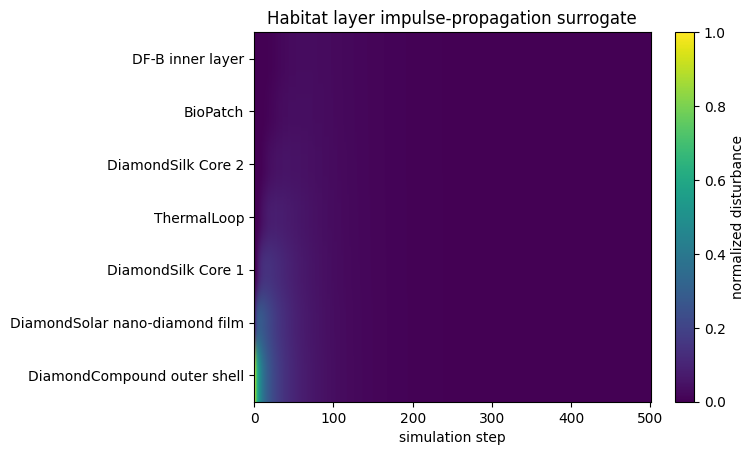

In [ ]:
HABITAT_LAYERS = [
    "DiamondCompound outer shell",
    "DiamondSolar nano-diamond film",
    "DiamondSilk Core 1",
    "ThermalLoop",
    "DiamondSilk Core 2",
    "BioPatch",
    "DF-B inner layer",
]


def habitat_layer_propagation(steps=500, coupling=0.12, damping=0.015, show=True):
    n = len(HABITAT_LAYERS)
    field = np.zeros(n)
    field[0] = 1.0
    history = [field.copy()]
    for _ in range(steps):
        lap = np.zeros(n)
        for i in range(n):
            if i > 0:
                lap[i] += field[i - 1] - field[i]
            if i < n - 1:
                lap[i] += field[i + 1] - field[i]
        field = (1 - damping) * field + coupling * lap
        history.append(field.copy())
    H = np.asarray(history)
    if show:
        plt.imshow(H.T, aspect="auto", origin="lower")
        plt.yticks(range(n), HABITAT_LAYERS)
        plt.xlabel("simulation step")
        plt.title("Habitat layer impulse-propagation surrogate")
        plt.colorbar(label="normalized disturbance")
        plt.show()
    return H

if RUN_SUITE_DEMOS:
    habitat_layer_propagation()

## 35. Material Stack Frequency Response

Explore a generic seven-stage low-pass surrogate across the canonical layer stack. The cutoff values are normalized demo parameters, not measured DiamondFlex properties.

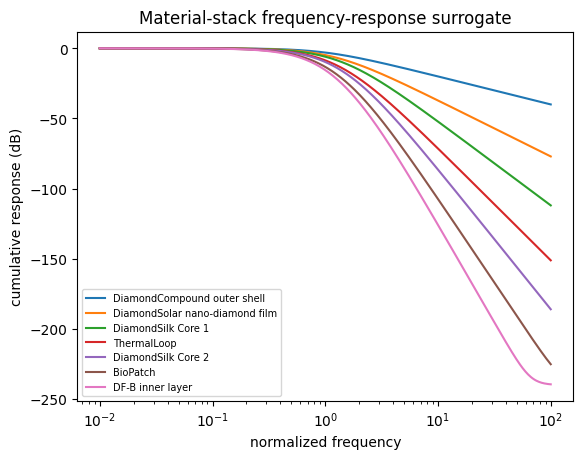

In [ ]:
def material_stack_frequency_response(cutoffs_demo=None, show=True):
    if cutoffs_demo is None:
        cutoffs_demo = np.array([1.0, 1.4, 1.8, 1.1, 1.8, 0.9, 1.2])
    cutoffs_demo = np.asarray(cutoffs_demo, dtype=float)
    if len(cutoffs_demo) != len(HABITAT_LAYERS):
        raise ValueError("Need one demo cutoff per canonical layer.")
    f = np.logspace(-2, 2, 500)
    cumulative = np.ones_like(f)
    responses = []
    for layer, fc in zip(HABITAT_LAYERS, cutoffs_demo):
        H = 1 / np.sqrt(1 + (f / fc) ** 2)
        cumulative = cumulative * H
        responses.append((layer, cumulative.copy()))
    if show:
        for layer, H in responses:
            plt.semilogx(f, 20 * np.log10(H + 1e-12), label=layer)
        plt.xlabel("normalized frequency")
        plt.ylabel("cumulative response (dB)")
        plt.title("Material-stack frequency-response surrogate")
        plt.legend(fontsize=7)
        plt.show()
    return f, responses

if RUN_SUITE_DEMOS:
    material_stack_frequency_response()

## 36. P2 Information Compression

Compare gzip and LZMA compression of exact recurrent P2 tokens against shuffled and random symbol streams of identical length. This is ordinary information/compression analysis only.

In [ ]:
def _encode_tokens(tokens):
    return ("|".join(tokens)).encode("utf-8")


def p2_information_compression(cycles=2000, seed=36):
    rng = np.random.default_rng(seed)
    exact = repeated_p2_tokens(cycles, include_delay=True)
    shuffled = exact.copy()
    rng.shuffle(shuffled)
    random_stream = rng.choice(UNIQUE_STATE_LABELS, size=len(exact), replace=True).tolist()
    rows = []
    for name, seq in [("exact_recurrence", exact), ("shuffled_same_symbols", shuffled), ("random_symbols", random_stream)]:
        raw = _encode_tokens(seq)
        rows.append({
            "case": name,
            "raw_bytes": len(raw),
            "gzip_bytes": len(gzip.compress(raw)),
            "lzma_bytes": len(lzma.compress(raw)),
        })
    df = pd.DataFrame(rows)
    df["gzip_ratio"] = df.gzip_bytes / df.raw_bytes
    df["lzma_ratio"] = df.lzma_bytes / df.raw_bytes
    return df

if RUN_SUITE_DEMOS:
    display(p2_information_compression())

,case,raw_bytes,gzip_bytes,lzma_bytes,gzip_ratio,lzma_ratio
0,exact_recurrence,77999,298,176,0.003821,0.002256
1,shuffled_same_symbols,77999,9310,8416,0.119361,0.107899
2,random_symbols,80155,9529,8636,0.118882,0.107741


## 37. P2 Entropy-of-Sequence Comparison

Calculate ordinary Shannon symbol entropy and first-order conditional entropy for exact, shuffled, random, and perturbed streams. This is information-theoretic entropy, explicitly separate from the user's physical entropy terminology.

In [ ]:
def shannon_entropy_symbols(seq):
    counts = Counter(seq)
    p = np.asarray(list(counts.values()), dtype=float)
    p /= p.sum()
    return float(-(p * np.log2(p)).sum())


def conditional_entropy_1(seq):
    pair = Counter(zip(seq[:-1], seq[1:]))
    first = Counter(seq[:-1])
    total = len(seq) - 1
    H = 0.0
    for (a, b), n_ab in pair.items():
        p_ab = n_ab / total
        p_b_given_a = n_ab / first[a]
        H -= p_ab * math.log2(p_b_given_a)
    return H


def p2_entropy_comparison(cycles=1000, seed=37):
    rng = np.random.default_rng(seed)
    exact = repeated_p2_tokens(cycles, include_delay=True)
    shuffled = exact.copy(); rng.shuffle(shuffled)
    random_seq = rng.choice(UNIQUE_STATE_LABELS, size=len(exact), replace=True).tolist()
    perturbed = exact.copy()
    for i in rng.choice(len(perturbed), size=max(1, len(perturbed)//50), replace=False):
        perturbed[i] = rng.choice(UNIQUE_STATE_LABELS)
    rows = []
    for name, seq in [("exact", exact), ("shuffled", shuffled), ("random", random_seq), ("perturbed", perturbed)]:
        rows.append((name, shannon_entropy_symbols(seq), conditional_entropy_1(seq)))
    return pd.DataFrame(rows, columns=["case", "symbol_entropy_bits", "conditional_entropy_bits"])

if RUN_SUITE_DEMOS:
    display(p2_entropy_comparison())

,case,symbol_entropy_bits,conditional_entropy_bits
0,exact,2.750000,0.250031
1,shuffled,2.750000,2.746905
2,random,2.806653,2.802764
3,perturbed,2.750112,0.535652


## 38. P2 Autocorrelation Signature

Encode the recurrent traversal as state IDs and calculate normalized autocorrelation. Peaks reveal periodicity in the chosen symbolic encoding.

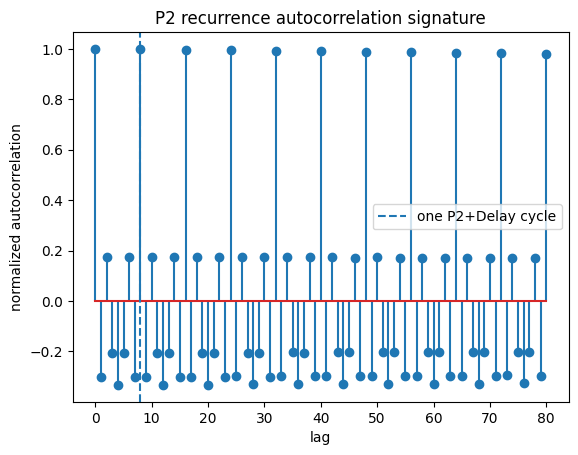

In [ ]:
def p2_autocorrelation_signature(cycles=500, max_lag=80, show=True):
    x = state_scalar_stream(cycles, include_delay=True)
    x = x - x.mean()
    corr = signal.correlate(x, x, mode="full", method="fft")
    corr = corr[len(x) - 1:]
    corr /= corr[0]
    lags = np.arange(min(max_lag + 1, len(corr)))
    vals = corr[:len(lags)]
    if show:
        plt.stem(lags, vals)
        plt.axvline(len(P2_CYCLE_TOKENS), linestyle="--", label="one P2+Delay cycle")
        plt.xlabel("lag")
        plt.ylabel("normalized autocorrelation")
        plt.title("P2 recurrence autocorrelation signature")
        plt.legend()
        plt.show()
    return lags, vals

if RUN_SUITE_DEMOS:
    p2_autocorrelation_signature()

## 39. P2 Fourier Fingerprint

Compare FFT magnitude spectra from multiple scalar encodings of the same repeated P2 traversal. The recurring period should remain visible even when the encoding changes.

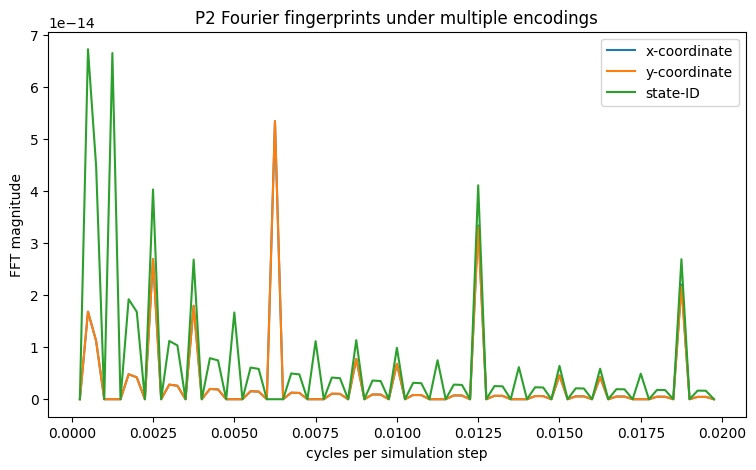

In [ ]:
def p2_fourier_fingerprint(cycles=500, show=True):
    xy = np.asarray(CANONICAL_P2, dtype=float)
    x_cycle = np.concatenate([xy[:, 0], [0.0]])
    y_cycle = np.concatenate([xy[:, 1], [0.0]])
    id_cycle = np.asarray([STATE_ID[s] for s in P2_CYCLE_TOKENS], dtype=float)
    encodings = {
        "x-coordinate": np.tile(x_cycle, cycles),
        "y-coordinate": np.tile(y_cycle, cycles),
        "state-ID": np.tile(id_cycle, cycles),
    }
    results = {}
    if show:
        plt.figure(figsize=(9, 5))
    for name, arr in encodings.items():
        arr = arr - arr.mean()
        spec = np.abs(np.fft.rfft(arr))
        freq = np.fft.rfftfreq(len(arr), d=1.0)
        results[name] = (freq, spec)
        if show:
            plt.plot(freq[1:80], spec[1:80], label=name)
    if show:
        plt.xlabel("cycles per simulation step")
        plt.ylabel("FFT magnitude")
        plt.title("P2 Fourier fingerprints under multiple encodings")
        plt.legend()
        plt.show()
    return results

if RUN_SUITE_DEMOS:
    p2_fourier_fingerprint()

## 40. Can an Algorithm Discover P2?

Hide exact P2 motifs inside a much larger random symbolic stream, then use unsupervised n-gram frequency mining to discover unusually repeated motifs. No canonical labels are given to the motif finder.

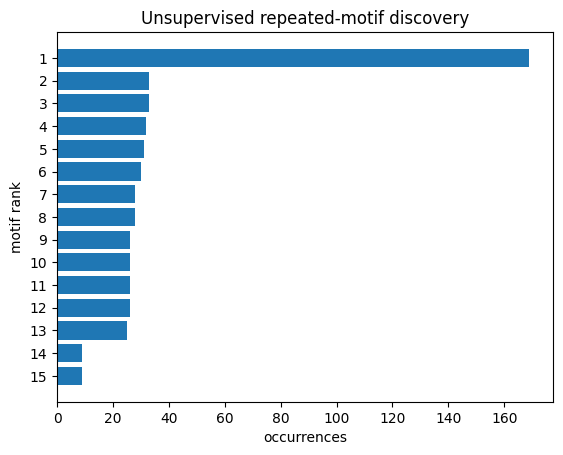

,rank,count,motif,matches_P2
0,1,169,"3,3 -> 0,0 -> 0,1 -> 1,2 -> 2,1 -> 1,0 -> 0,0",True
1,2,33,"0,0 -> 0,1 -> 1,2 -> 2,1 -> 1,0 -> 0,0 -> 0,0",False
2,3,33,"0,1 -> 3,3 -> 0,0 -> 0,1 -> 1,2 -> 2,1 -> 1,0",False
3,4,32,"3,3 -> 3,3 -> 0,0 -> 0,1 -> 1,2 -> 2,1 -> 1,0",False
4,5,31,"0,0 -> 0,1 -> 1,2 -> 2,1 -> 1,0 -> 0,0 -> 1,0",False
5,6,30,"2,1 -> 3,3 -> 0,0 -> 0,1 -> 1,2 -> 2,1 -> 1,0",False
6,7,28,"0,0 -> 0,1 -> 1,2 -> 2,1 -> 1,0 -> 0,0 -> 0,1",False
7,8,28,"0,0 -> 0,1 -> 1,2 -> 2,1 -> 1,0 -> 0,0 -> 2,1",False
8,9,26,"1,0 -> 3,3 -> 0,0 -> 0,1 -> 1,2 -> 2,1 -> 1,0",False
9,10,26,"1,2 -> 3,3 -> 0,0 -> 0,1 -> 1,2 -> 2,1 -> 1,0",False


In [ ]:
def discover_p2_motif(random_length=20000, insertions=180, motif_length=7, seed=40, show=True):
    rng = np.random.default_rng(seed)
    alphabet = P2_LABELS[:-1]  # symbolic pool; duplicated label value removed naturally
    stream = rng.choice(alphabet, size=random_length, replace=True).tolist()
    motif = P2_LABELS.copy()
    valid_positions = rng.choice(random_length - len(motif), size=insertions, replace=False)
    for pos in valid_positions:
        stream[pos:pos + len(motif)] = motif

    counts = Counter(tuple(stream[i:i + motif_length]) for i in range(len(stream) - motif_length + 1))
    top = counts.most_common(15)
    df = pd.DataFrame([
        {"rank": i + 1, "count": count, "motif": " -> ".join(seq), "matches_P2": list(seq) == motif}
        for i, (seq, count) in enumerate(top)
    ])
    if show:
        plt.barh(df["rank"].astype(str), df["count"])
        plt.gca().invert_yaxis()
        plt.xlabel("occurrences")
        plt.ylabel("motif rank")
        plt.title("Unsupervised repeated-motif discovery")
        plt.show()
        display(df)
    return df, stream

if RUN_SUITE_DEMOS:
    discover_p2_motif()

# Suite Index and Smoke Tests

The cells below verify that representative functions from every major simulation family can run without changing the canonical P2 constant. They intentionally avoid rendering all 40 visualizations during a normal top-to-bottom execution.

In [ ]:
SIMULATION_INDEX = [
    "1 P3 Shadow Projection",
    "2 Echo Meridian Alignment Field",
    "3 Temporal Ordering Without a Clock",
    "4 Delay(200) Removal Test",
    "5 P2 Sequence Mutation Detector",
    "6 Missing-State Reconstruction",
    "7 Zero-Return Failure Simulation",
    "8 0,0 Context Classifier",
    "9 EchoLift/RosenEcho Collision",
    "10 Traversal Phase Portrait",
    "11 P2 Recurrence Spectrogram",
    "12 Tensor Fingerprint",
    "13 P3 Dimensional Survival Test",
    "14 P3 Axis Failure",
    "15 P3 Phase-Locking Map",
    "16 Resonance Reinforcement Heatmap",
    "17 P3 Nested Sphere",
    "18 Echo Meridian + P3 Combined Geometry",
    "19 Resonance Recoil Layer Formation",
    "20 LDCT Emergence",
    "21 LDCT Cut Test",
    "22 DiamondFlex Nano-Diamond Ensemble",
    "23 DiamondFlex Routing Maze",
    "24 DiamondFlex Defect Propagation",
    "25 DiamondFlex Full-P2 Node Synchronization",
    "26 QRTM Phase-Correlation Cloud",
    "27 QRTM Threshold Boundary",
    "28 QRTM Spike Injection",
    "29 Wilson Branch-Growth Simulation",
    "30 Wilson Unresolved Fragment Memory",
    "31 Wilson False-Context Rejection",
    "32 Kernel vs Phenotype Growth",
    "33 Artificial-Gravity Ring Coupling",
    "34 Habitat Layer Propagation",
    "35 Material Stack Frequency Response",
    "36 P2 Information Compression",
    "37 P2 Entropy-of-Sequence Comparison",
    "38 P2 Autocorrelation Signature",
    "39 P2 Fourier Fingerprint",
    "40 Can an Algorithm Discover P2?",
]

print("\n".join(SIMULATION_INDEX))

1 P3 Shadow Projection
2 Echo Meridian Alignment Field
3 Temporal Ordering Without a Clock
4 Delay(200) Removal Test
5 P2 Sequence Mutation Detector
6 Missing-State Reconstruction
7 Zero-Return Failure Simulation
8 0,0 Context Classifier
9 EchoLift/RosenEcho Collision
10 Traversal Phase Portrait
11 P2 Recurrence Spectrogram
12 Tensor Fingerprint
13 P3 Dimensional Survival Test
14 P3 Axis Failure
15 P3 Phase-Locking Map
16 Resonance Reinforcement Heatmap
17 P3 Nested Sphere
18 Echo Meridian + P3 Combined Geometry
19 Resonance Recoil Layer Formation
20 LDCT Emergence
21 LDCT Cut Test
22 DiamondFlex Nano-Diamond Ensemble
23 DiamondFlex Routing Maze
24 DiamondFlex Defect Propagation
25 DiamondFlex Full-P2 Node Synchronization
26 QRTM Phase-Correlation Cloud
27 QRTM Threshold Boundary
28 QRTM Spike Injection
29 Wilson Branch-Growth Simulation
30 Wilson Unresolved Fragment Memory
31 Wilson False-Context Rejection
32 Kernel vs Phenotype Growth
33 Artificial-Gravity Ring Coupling
34 Habitat La

In [ ]:
# Lightweight smoke tests: no large plots, no canonical mutation.
assert tuple(P2_KERNEL) == CANONICAL_P2
assert reconstruct_without_clock(cycles=20)["exact_match"]
assert zero_return_failure_test(show=False).loc[0, "returned_to_0_0"]
assert not zero_return_failure_test(show=False).loc[1, "returned_to_0_0"]
assert len(tensor_fingerprint()) > 0
assert p3_dimensional_survival(dimensions=(3, 4), show=False)["pairwise_geometry_spearman"].notna().all()
assert len(ldct_cut_test(ldct_emergence(n=50, show=False), fractions=[0, 0.2], show=False)) == 4
assert diamondflex_ensemble(n_nodes=100, steps=5, show=False).shape == (5, len(P2_CYCLE_TOKENS))
assert len(qrtm_spike_injection(spike_sizes=[0, 1], show=False)) == 2
assert _kernel_hash() == hashlib.sha256(repr(CANONICAL_P2).encode("utf-8")).hexdigest()
assert len(p2_information_compression(cycles=5)) == 3
assert len(p2_entropy_comparison(cycles=5)) == 4
assert tuple(P2_KERNEL) == CANONICAL_P2

print("Extended simulation suite smoke tests passed.")

Extended simulation suite smoke tests passed.
